<p align="center">
  <img src="assets/hero_kavram.svg" width="100%" alt="Gün 51 — LightGBM: Yaprak Yaprak Büyüyen Hız Ustası">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-51-7C3AED?style=for-the-badge" alt="Gün 51">
  <img src="https://img.shields.io/badge/Konu-LightGBM_(Kavram)-F6B84B?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7-16A34A?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/LightGBM-4.7-0F172A?style=for-the-badge" alt="LightGBM">
  <img src="https://img.shields.io/badge/Animasyon-5_GIF-D1495B?style=for-the-badge" alt="Animasyon">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🪣</h3><b>Kova hilesi</b><br><br>Sayıları <b>kovalara</b> atıp<br>bölünmeyi kovalar arasında ara<br><br></td><td width="25%" valign="top" align="center"><h3>🍃</h3><b>Yaprak yaprak</b><br><br>Ağacı katman katman değil,<br><b>en yangın çıkan yaprağı</b> büyüterek kur<br><br></td><td width="25%" valign="top" align="center"><h3>🎯</h3><b>GOSS</b><br><br>Çok yanılan örneklere odaklan,<br>kolay olanlardan <b>az örnek</b> al<br><br></td><td width="25%" valign="top" align="center"><h3>📦</h3><b>EFB</b><br><br>Aynı anda dolu olmayan<br>seyrek sütunları <b>tek sütunda</b> topla<br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🍃 LightGBM'in **"usta ve çıraklar"** fikrini (hata → yeni ağaç → güncelle) bir kâğıt üzerinde, **8 mahalleyle**, elle hesaplayarak anlatmak
- 🧮 Elle bulduğunuz her sayıyı **gerçek `lightgbm`** ile doğrulamak
- 🪣 LightGBM'i hızlı yapan **dört hileyi** (histogram, yaprak yaprak büyüme, GOSS, EFB) *neden işe yaradıklarıyla* açıklamak
- 🛡️ **Küçük veride** hangi düğmelerin (`min_child_samples`, `num_leaves`, λ) ezberi önlediğini görmek
- ⚡ LightGBM'in diğer boosting kütüphanelerine göre **hızını** kendi bilgisayarınızda ölçmek
- 🧪 **60 satırlık bir "mini LightGBM"** yazıp gerçek kütüphaneyle karşılaştırmak

Teknik ayrıntı bilinçli olarak az tutuldu; her kavramın yanında **bir resim, bir animasyon ve bir deney** var.

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_kavram.svg" width="100%" alt="Kavram yol haritası: 14 durak">
</p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Ana soru |
|:-:|:--|:--|
| 🧰 1 | [Kurulum](#p1) | Hangi araçlarla çalışıyoruz? |
| 💡 2 | [Büyük fikir](#p2) | Boosting nedir, LightGBM neyi farklı yapar? |
| 🔁 3 | [Beş adımlık döngü](#p3) | Model nasıl öğrenir? |
| 🎲 4 | [Başlangıç tahmini](#p4) | İlk tahmin ne olmalı? |
| ❌ 5 | [Hata (artık)](#p5) | Model nerede yanılıyor? |
| ✂️ 6 | [Bölünme ve yaprak](#p6) | Ağaç nereden bölünür, yaprağa ne yazılır? |
| 🪣 7 | [Hile 1: Histogram](#p7) | Sayıları kovalamak neden hızlandırır? |
| 🍃 8 | [Hile 2: Yaprak yaprak büyüme](#p8) | Katman katman mı, yaprak yaprak mı? |
| 🎯 9 | [Hile 3: GOSS](#p9) | Tüm örneklere bakmak şart mı? |
| 📦 10 | [Hile 4: EFB](#p10) | Seyrek sütunlar nasıl paketlenir? |
| 🛡️ 11 | [Frenler ve düğmeler](#p11) | Küçük veride ezberi ne önler? |
| ⚡ 12 | [Hız yarışı](#p12) | LightGBM gerçekten hızlı mı? |
| 🧪 13 | [Sıfırdan mini LightGBM](#p13) | Gerçek kütüphaneyle örtüşüyor mu? |
| 🎓 14 | [Özet](#p14) | Akılda kalanlar, quiz, ödevler, kaynakça |

<a id="p1"></a>

<p align="center">
  <img src="assets/kavram_01.svg" width="100%" alt="Bölüm 1">
</p>

Kütüphaneleri ve çizim yardımcılarını tek hücrede topluyoruz. Animasyonlar `outputs/figures` klasörüne **GIF** olarak kaydedilir ve notebook içinde oynatılır.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import lightgbm as lgb
import xgboost
import catboost
import sklearn
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter

from lightgbm import LGBMClassifier
from sklearn.datasets import make_classification, make_moons
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from boston_yardimci import SINIF_ADLARI, veri_oku

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
RANDOM_STATE = 42
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

RENK = {"altin": "#EDAE49", "mor": "#6C5CE7", "pembe": "#D1495B", "mavi": "#2B6CB0",
        "yesil": "#2E9E6B", "turuncu": "#E8833A", "gri": "#8A94A6", "koyu": "#2E4057", "cyan": "#0E9AA7"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.25})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    fig.savefig(FIG_DIR / f"{ad}.png")
    print(f"💾 Kaydedildi → outputs/figures/{ad}.png")


def gif_kaydet(kare_ciz, n_kare, ad, figsize=(7, 4), fps=2, dpi=70):
    """kare_ciz(fig, i) ile her kareyi çizip animasyonlu GIF olarak kaydeder ve ekranda oynatır."""
    yol = FIG_DIR / f"{ad}.gif"
    fig = plt.figure(figsize=figsize)
    anim = FuncAnimation(fig, lambda i: kare_ciz(fig, i), frames=n_kare)
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    print(f"💾 Animasyon → {yol.as_posix()} ({yol.stat().st_size / 1024:.0f} KB)")
    display(Image(filename=str(yol)))


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


print(f"LightGBM {lgb.__version__} · XGBoost {xgboost.__version__} · CatBoost {catboost.__version__} · scikit-learn {sklearn.__version__} · numpy {np.__version__}")

LightGBM 4.7.0 · XGBoost 3.4.1 · CatBoost 1.2.10 · scikit-learn 1.9.1 · numpy 2.5.3


<a id="p2"></a>

<p align="center">
  <img src="assets/kavram_02.svg" width="100%" alt="Bölüm 2">
</p>

### 💡 2.1 · Usta ve Çıraklar

Tek bir karar ağacı, **tek bir usta** gibidir: bir şey öğrenir ama gürültüye de kapılır. **Boosting** farklı çalışır: önce **küçük bir çırak** (basit bir ağaç) bir tahmin yapar. Sonraki çırak yalnızca **ilk çırağın yaptığı hatalara** bakar ve onları düzeltmeye çalışır. Üçüncüsü ikincinin kalan hatalarına bakar… Yüzlerce küçük çırak, **birbirinin eksiğini kapatarak** güçlü bir ekip olur.

LightGBM (Ke vd., 2017), bu fikri değiştirmez; yalnızca **çok daha hızlı ve hafıf** çalıştırır. Hızını **dört hileye** borçludur; bu notebook'un omurgası bu dört hile:

<p align="center">
  <img src="assets/diyagram_hileler.svg" width="100%" alt="LightGBM'in dört hilesi">
</p>

💾 Kaydedildi → outputs/figures/kavram_01_tek_model_mi_ekip_mi.png


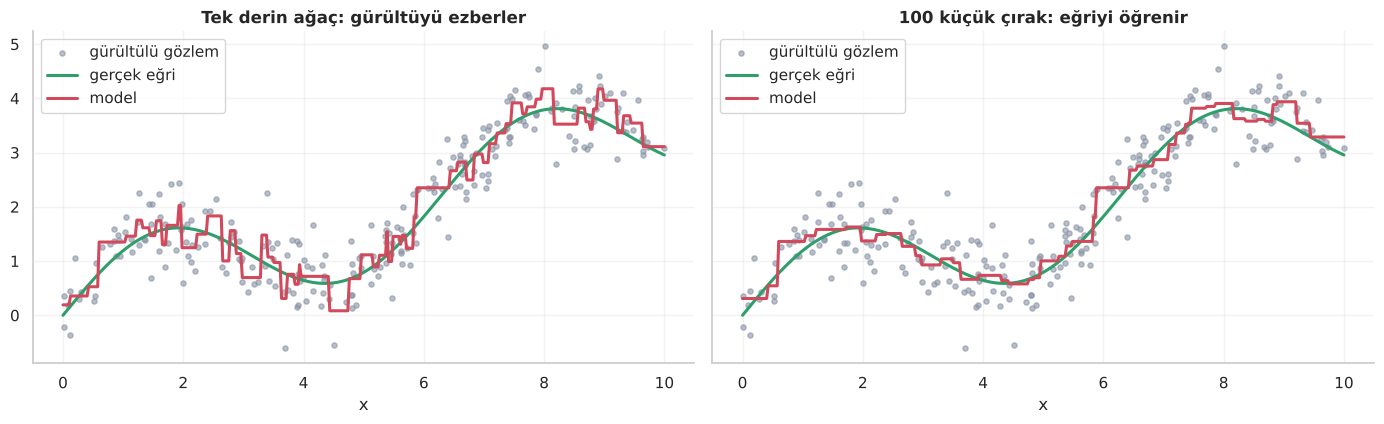

In [2]:
# Gürültülü bir eğri üzerinde: tek ağaç mı, 100 küçük ağaçlı ekip mi?
rng = np.random.default_rng(3)
x = np.sort(rng.uniform(0, 10, 260)); gercek = np.sin(x) + 0.35 * x
y_gur = gercek + rng.normal(0, 0.45, len(x))
izgara = np.linspace(0, 10, 400)[:, None]

tek = lgb.LGBMRegressor(n_estimators=1, learning_rate=1.0, num_leaves=64, min_child_samples=3, verbosity=-1).fit(x[:, None], y_gur)
ekip = lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1, num_leaves=4, min_child_samples=8, verbosity=-1).fit(x[:, None], y_gur)
fig, eksen = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, m, baslik in zip(eksen, [tek, ekip], ["Tek derin ağaç: gürültüyü ezberler", "100 küçük çırak: eğriyi öğrenir"]):
    ax.scatter(x, y_gur, s=14, color=RENK["gri"], alpha=0.6, label="gürültülü gözlem")
    ax.plot(izgara, np.sin(izgara) + 0.35 * izgara, color=RENK["yesil"], lw=2.2, label="gerçek eğri")
    ax.plot(izgara, m.predict(izgara), color=RENK["pembe"], lw=2.2, label="model")
    ax.set(title=baslik, xlabel="x"); ax.legend(loc="upper left")
plt.tight_layout()
kaydet(fig, "kavram_01_tek_model_mi_ekip_mi")
plt.show()

### 🧬 2.2 · Aile Ağacı: LightGBM Nereden Geliyor?

<p align="center">
  <img src="assets/diyagram_aile.svg" width="100%" alt="Boosting ailesi">
</p>

Fikir, **Gradient Boosting** (Friedman, 2001) ile başladı; **XGBoost** (Chen ve Guestrin, 2016) düzenleme terimleri ve sistem mühendisliği ekledi; **LightGBM** (Ke vd., 2017) histogram, yaprak yaprak büyüme, GOSS ve EFB ile hızı artırdı; **CatBoost** (Prokhorenkova vd., 2018) kategorik sütunları ele alışıyla öne çıktı. **Aynı temel döngü**, farklı mühendislik.

<a id="p3"></a>

<p align="center">
  <img src="assets/kavram_03.svg" width="100%" alt="Bölüm 3">
</p>

LightGBM'in tüm öğrenme süreci **beş adımın tekrarıdır**. Hepsini kâğıt üzerinde göreceğiz:

<p align="center">
  <img src="assets/diyagram_dongu.svg" width="100%" alt="Beş adımlık döngü">
</p>

Örneğimiz **8 mahalle**: her birinin **ortalama oda sayısı** (`RM`) ve **premium olup olmadığı** var. Soru: *hangi mahalleler premium?*

In [3]:
mahalle = pd.DataFrame({"Mahalle": list("ABCDEFGH"), "RM (oda)": [5.4, 5.8, 6.1, 6.4, 6.7, 7.0, 7.3, 7.8], "Premium (1/0)": [0, 0, 1, 0, 0, 1, 1, 1]})
X_oyuncak = mahalle[["RM (oda)"]].rename(columns={"RM (oda)": "RM"})
y_oyuncak = mahalle["Premium (1/0)"].to_numpy()
display(mahalle.set_index("Mahalle").T)
print("Premium sayısı:", y_oyuncak.sum(), "/", len(y_oyuncak))

Mahalle,A,B,C,D,E,F,G,H
RM (oda),5.4,5.8,6.1,6.4,6.7,7.0,7.3,7.8
Premium (1/0),0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0


Premium sayısı: 4 / 8


<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

**Dikkat:** C mahallesi (6,1 oda) premium ama komşuları değil. Gerçek veride de her zaman böyle **sürprizler** olur; model bunları ne kadar ciddiye alacak, bu notebook'un konularından biri.

</td></tr></table>

<a id="p4"></a>

<p align="center">
  <img src="assets/kavram_04.svg" width="100%" alt="Bölüm 4">
</p>

### 🎲 4.1 · İlk Tahmin: "Ortalamayı Söyle"

Hiçbir şey bilmeden tahmin yapmak zorundaysak, **en mantıklı cevap ortalamadır**: 8 mahallenin 4'ü premium → "her mahalle %50 olasılıkla premium". LightGBM bu olasılığı doğrudan değil, **log-odds** denen bir ölçekte tutar (çünkü toplamak kolaydır): `log-odds = ln(p / (1−p))`. %50 olasılık, log-odds'ta **0**'dır. Olasılığa dönüş **sigmoid** ile yapılır: `p = 1 / (1 + e^(−log-odds))`.

Başlangıç olasılığı p₀ = 0.50  →  log-odds = 0.00  →  sigmoid geri dönüşü = 0.50


💾 Kaydedildi → outputs/figures/kavram_02_sigmoid.png


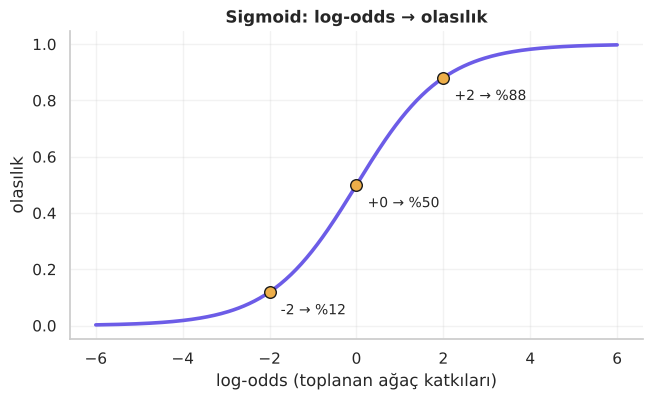

In [4]:
p0 = y_oyuncak.mean()
log_odds_0 = np.log(p0 / (1 - p0))
print(f"Başlangıç olasılığı p₀ = {p0:.2f}  →  log-odds = {log_odds_0:.2f}  →  sigmoid geri dönüşü = {sigmoid(log_odds_0):.2f}")

x_s = np.linspace(-6, 6, 300)
fig, ax = plt.subplots(figsize=(7.4, 4))
ax.plot(x_s, sigmoid(x_s), lw=2.6, color=RENK["mor"])
for lo in (-2, 0, 2):
    ax.scatter(lo, sigmoid(lo), s=70, color=RENK["altin"], zorder=3, edgecolor="k"); ax.annotate(f"{lo:+d} → %{sigmoid(lo) * 100:.0f}", (lo, sigmoid(lo)), xytext=(8, -16), textcoords="offset points", fontsize=10)
ax.set(title="Sigmoid: log-odds → olasılık", xlabel="log-odds (toplanan ağaç katkıları)", ylabel="olasılık")
kaydet(fig, "kavram_02_sigmoid")
plt.show()

<a id="p5"></a>

<p align="center">
  <img src="assets/kavram_05.svg" width="100%" alt="Bölüm 5">
</p>

### ❌ 5.1 · Artık: Her Mahalle Ne Kadar Yanlış?

**Artık = gerçek − tahmin.** Premium mahalle için `1 − 0,5 = +0,5` (olasılığı yükseltmeliyiz), standart için `0 − 0,5 = −0,5` (düşürmeliyiz). Bir sonraki çırak **bu artıkları** tahmin etmeye çalışacak.

Mahalle,A,B,C,D,E,F,G,H
RM (oda),5.40,5.80,6.10,6.40,6.70,7.00,7.30,7.80
Premium (1/0),0.00,0.00,1.00,0.00,0.00,1.00,1.00,1.00
p (tahmin),0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50
Artık = gerçek − p,-0.50,-0.50,0.50,-0.50,-0.50,0.50,0.50,0.50
Belirsizlik p(1−p),0.25,0.25,0.25,0.25,0.25,0.25,0.25,0.25


💾 Kaydedildi → outputs/figures/kavram_03_ilk_artiklar.png


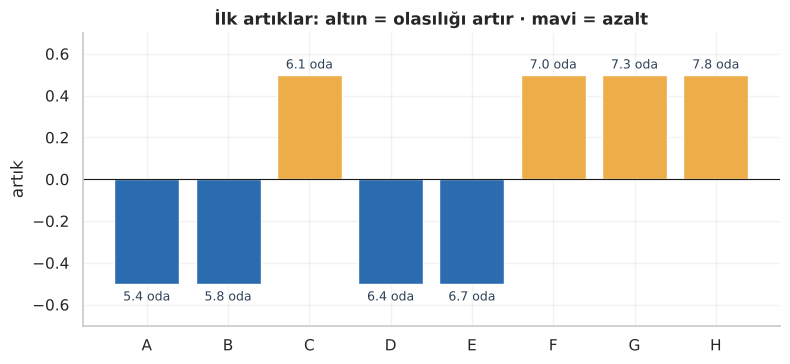

In [5]:
mahalle["p (tahmin)"] = p0
mahalle["Artık = gerçek − p"] = mahalle["Premium (1/0)"] - mahalle["p (tahmin)"]
mahalle["Belirsizlik p(1−p)"] = mahalle["p (tahmin)"] * (1 - mahalle["p (tahmin)"])
display(mahalle.set_index("Mahalle").T.round(2))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(mahalle["Mahalle"], mahalle["Artık = gerçek − p"], color=[RENK["altin"] if v > 0 else RENK["mavi"] for v in mahalle["Artık = gerçek − p"]], edgecolor="white")
ax.axhline(0, color="k", lw=0.8)
for i, (m, v, r) in enumerate(zip(mahalle["Mahalle"], mahalle["Artık = gerçek − p"], mahalle["RM (oda)"])):
    ax.text(i, v + (0.03 if v > 0 else -0.08), f"{r} oda", ha="center", fontsize=9, color=RENK["koyu"])
ax.set(title="İlk artıklar: altın = olasılığı artır · mavi = azalt", ylabel="artık", ylim=(-0.7, 0.7))
kaydet(fig, "kavram_03_ilk_artiklar")
plt.show()

<a id="p6"></a>

<p align="center">
  <img src="assets/kavram_06.svg" width="100%" alt="Bölüm 6">
</p>

### ✂️ 6.1 · En İyi Bölünme: Gain

Yeni çırak, mahalleleri **oda sayısına göre ikiye böler** ("RM ≤ eşik mi?"). Hangi eşik en iyisi? Her aday eşik için **gain** (kazanç) hesaplanır: *bölünme, artıkları ne kadar düzenli gruplara ayırıyor?* Aynı işaretli artıklar bir yaprakta toplanırsa gain **yüksek** olur; karışık işaretler **birbirini götürüp** gain'i düşürür.

Formül basit: her yaprak için `(artıkların toplamı)² / (belirsizlik toplamı + λ)`; iki yaprağı topla, bölünmeden önceki değeri çıkar. (`λ` = 1, aşırı güveni frenleyen küçük bir sayı.)

,eşik (RM ≤),sol yaprak,sağ yaprak,sol artık toplamı,sağ artık toplamı,gain
0,5.60,A,BCDEFGH,-0.5,0.5,0.291
1,5.95,AB,CDEFGH,-1.0,1.0,1.067
2,6.25,ABC,DEFGH,-0.5,0.5,0.254
3,6.55,ABCD,EFGH,-1.0,1.0,1.000
4,6.85,ABCDE,FGH,-1.5,1.5,2.286
5,7.15,ABCDEF,GH,-1.0,1.0,1.067
6,7.55,ABCDEFG,H,-0.5,0.5,0.291



✔ En iyi eşik: RM ≤ 6.85  (gain 2.2857)  →  sol: ABCDE  ·  sağ: FGH
💾 Kaydedildi → outputs/figures/kavram_04_aday_bolunmeler.png


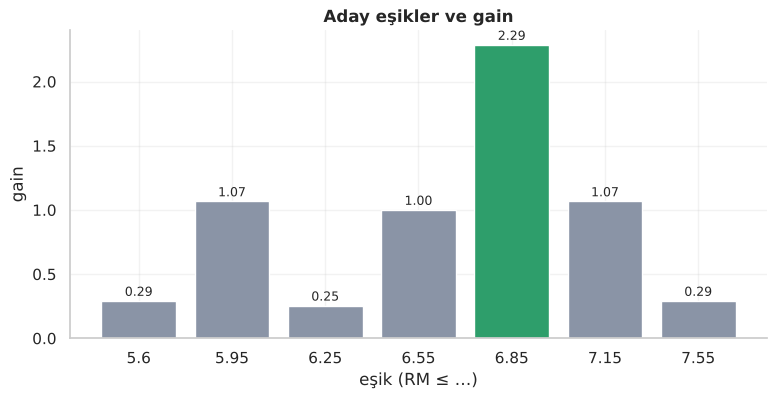

In [6]:
LAM = 1.0                                                       # λ: düzenleme (fren) katsayısı
r = (y_oyuncak - p0); h = np.full(len(y_oyuncak), p0 * (1 - p0)); rm = X_oyuncak["RM"].to_numpy()


def yaprak_puani(r_, h_):
    return r_.sum() ** 2 / (h_.sum() + LAM)


adaylar = []
for k in range(1, len(rm)):
    sol, sag = slice(0, k), slice(k, None)
    kazanc = yaprak_puani(r[sol], h[sol]) + yaprak_puani(r[sag], h[sag]) - yaprak_puani(r, h)
    adaylar.append({"eşik (RM ≤)": (rm[k - 1] + rm[k]) / 2, "sol yaprak": "".join(mahalle["Mahalle"][:k]), "sağ yaprak": "".join(mahalle["Mahalle"][k:]),
                    "sol artık toplamı": r[sol].sum(), "sağ artık toplamı": r[sag].sum(), "gain": kazanc})
adaylar = pd.DataFrame(adaylar)
display(adaylar.round(3))
en_iyi = adaylar.loc[adaylar["gain"].idxmax()]
print(f"\n✔ En iyi eşik: RM ≤ {en_iyi['eşik (RM ≤)']:.2f}  (gain {en_iyi['gain']:.4f})  →  sol: {en_iyi['sol yaprak']}  ·  sağ: {en_iyi['sağ yaprak']}")

fig, ax = plt.subplots(figsize=(9, 4))
cubuk = ax.bar(adaylar["eşik (RM ≤)"].round(2).astype(str), adaylar["gain"], color=[RENK["yesil"] if g == adaylar["gain"].max() else RENK["gri"] for g in adaylar["gain"]], edgecolor="white")
for c, g in zip(cubuk, adaylar["gain"]): ax.text(c.get_x() + c.get_width() / 2, g + 0.04, f"{g:.2f}", ha="center", fontsize=9)
ax.set(title="Aday eşikler ve gain", xlabel="eşik (RM ≤ …)", ylabel="gain")
kaydet(fig, "kavram_04_aday_bolunmeler")
plt.show()

### 🎞️ 6.2 · Bölünme Tarayıcısı (Animasyon)

Aşağıdaki animasyonda tarayıcı eşiği soldan sağa kaydırıyor. Her adımda **iki yaprağın artık toplamları** ve **gain** görülüyor. Yeşil çizgi, en iyi eşiğin üzerinde durduğu an.

💾 Animasyon → outputs/figures/kavram_05_bolunme_tarayici.gif (54 KB)


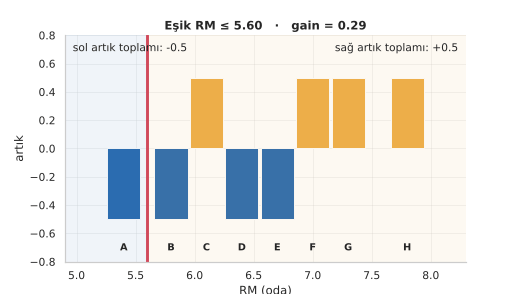

In [7]:
def kare_tarayici(fig, i):
    fig.clf(); ax = fig.add_subplot(111)
    k = i + 1; esik = (rm[k - 1] + rm[k]) / 2; g = adaylar["gain"].iloc[i]; en = g == adaylar["gain"].max()
    renkler = [RENK["altin"] if v > 0 else RENK["mavi"] for v in r]
    ax.bar(rm, r, width=0.28, color=renkler, edgecolor="white")
    ax.axvline(esik, color=RENK["yesil"] if en else RENK["pembe"], lw=3)
    ax.axvspan(rm.min() - 0.5, esik, color=RENK["mavi"], alpha=0.07); ax.axvspan(esik, rm.max() + 0.5, color=RENK["altin"], alpha=0.07)
    ax.text(0.02, 0.93, f"sol artık toplamı: {r[:k].sum():+.1f}", transform=ax.transAxes, fontsize=11); ax.text(0.98, 0.93, f"sağ artık toplamı: {r[k:].sum():+.1f}", transform=ax.transAxes, ha="right", fontsize=11)
    ax.set(title=f"Eşik RM ≤ {esik:.2f}   ·   gain = {g:.2f}" + ("   ✔ EN İYİ" if en else ""), xlabel="RM (oda)", ylabel="artık", ylim=(-0.8, 0.8), xlim=(rm.min() - 0.5, rm.max() + 0.5))
    for m_, x_ in zip(mahalle["Mahalle"], rm): ax.text(x_, -0.72, m_, ha="center", fontsize=10, fontweight="bold")


gif_kaydet(kare_tarayici, len(adaylar), "kavram_05_bolunme_tarayici", figsize=(7.4, 4.2), fps=1.4)

### 🍂 6.3 · Yaprak Değeri ve Güncelleme

Her yaprağa yazılacak sayı: `yaprak değeri = (artıkların toplamı) / (belirsizlik toplamı + λ)`. Bu değer, **öğrenme hızı (η)** ile çarpılıp mevcut log-odds'a **eklenir**. η küçükse çıraklar **küçük adımlar** atar: yavaş ama sağlam. Burada η = 0,3 kullanıyoruz.

In [8]:
ETA = 0.3
sol_mask = rm <= en_iyi["eşik (RM ≤)"]
yaprak_sol = r[sol_mask].sum() / (h[sol_mask].sum() + LAM)
yaprak_sag = r[~sol_mask].sum() / (h[~sol_mask].sum() + LAM)
print(f"Sol yaprak: Σartık = {r[sol_mask].sum():+.2f}, Σbelirsizlik = {h[sol_mask].sum():.2f}  →  değer = {yaprak_sol:+.4f}  →  η ile çarpınca {ETA * yaprak_sol:+.4f}")
print(f"Sağ yaprak: Σartık = {r[~sol_mask].sum():+.2f}, Σbelirsizlik = {h[~sol_mask].sum():.2f}  →  değer = {yaprak_sag:+.4f}  →  η ile çarpınca {ETA * yaprak_sag:+.4f}")

log_odds_1 = log_odds_0 + ETA * np.where(sol_mask, yaprak_sol, yaprak_sag)
p1 = sigmoid(log_odds_1)
sonuc = mahalle[["Mahalle", "RM (oda)", "Premium (1/0)"]].assign(**{"p önce": p0, "log-odds sonra": log_odds_1, "p sonra": p1})
display(sonuc.set_index("Mahalle").T.round(3))

Sol yaprak: Σartık = -1.50, Σbelirsizlik = 1.25  →  değer = -0.6667  →  η ile çarpınca -0.2000
Sağ yaprak: Σartık = +1.50, Σbelirsizlik = 0.75  →  değer = +0.8571  →  η ile çarpınca +0.2571


Mahalle,A,B,C,D,E,F,G,H
RM (oda),5.40,5.80,6.10,6.40,6.70,7.000,7.300,7.800
Premium (1/0),0.00,0.00,1.00,0.00,0.00,1.000,1.000,1.000
p önce,0.50,0.50,0.50,0.50,0.50,0.500,0.500,0.500
log-odds sonra,-0.20,-0.20,-0.20,-0.20,-0.20,0.257,0.257,0.257
p sonra,0.45,0.45,0.45,0.45,0.45,0.564,0.564,0.564


### ✅ 6.4 · Gerçek Kütüphane Aynı Şeyi Yapıyor mu?

Elle bulduğumuz her sayıyı **gerçek `lightgbm`** ile karşılaştırıyoruz. (Küçük veri olduğu için LightGBM'in `min_child_samples`, `min_data_in_bin` gibi güvenlik frenlerini 1'e indiriyoruz; yoksa 8 satırda hiç bölünmez; bunu bölüm 11'de ayrıca göreceğiz.)

In [9]:
OYUNCAK_AYAR = dict(num_leaves=2, min_child_samples=1, min_child_weight=0, min_data_in_bin=1, reg_lambda=LAM, learning_rate=ETA, verbosity=-1, n_jobs=1)
model_1 = LGBMClassifier(n_estimators=1, **OYUNCAK_AYAR).fit(X_oyuncak, y_oyuncak)
agac = model_1.booster_.trees_to_dataframe()
display(agac[["node_index", "split_feature", "threshold", "split_gain", "value", "count"]])
gercek_logodds = model_1.predict(X_oyuncak, raw_score=True)

karsilastir = pd.DataFrame({"büyüklük": ["eşik", "gain", "sol yaprak (η ile)", "sağ yaprak (η ile)", "8 mahallenin log-odds'u (en büyük fark)"],
                            "elle": [en_iyi["eşik (RM ≤)"], en_iyi["gain"], ETA * yaprak_sol, ETA * yaprak_sag, 0.0],
                            "lightgbm": [float(agac.loc[0, "threshold"]), float(agac.loc[0, "split_gain"]), float(agac[agac.node_index == "0-L0"]["value"].iloc[0]),
                                          float(agac[agac.node_index == "0-L1"]["value"].iloc[0]), float(np.abs(gercek_logodds - log_odds_1).max())]})
display(karsilastir.round(5))
print("Elle hesap = gerçek kütüphane mi?", np.allclose(gercek_logodds, log_odds_1, atol=1e-6))

,node_index,split_feature,threshold,split_gain,value,count
0,0-S0,RM,6.85,2.28571,0.000000,8
1,0-L0,NaN,NaN,NaN,-0.200000,5
2,0-L1,NaN,NaN,NaN,0.257143,3


,büyüklük,elle,lightgbm
0,eşik,6.85000,6.85000
1,gain,2.28571,2.28571
2,sol yaprak (η ile),-0.20000,-0.20000
3,sağ yaprak (η ile),0.25714,0.25714
4,8 mahallenin log-odds'u (en büyük fark),0.00000,0.00000


Elle hesap = gerçek kütüphane mi? True


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

**Elle hesapladığımız eşik, gain, yaprak değerleri ve 8 mahallenin yeni log-odds'u gerçek `lightgbm` ile birebir aynı çıktı.** Yani LightGBM'in "sihri" bu kadar: *artıkları gruplara ayır, her gruba bir düzeltme yaz, küçük adımla ekle.* Hız hileleri bu temel döngüyü **değiştirmez**, sadece hızlandırır.

</td></tr></table>

### 🎞️ 6.5 · Tur Tur Öğrenen Model (Animasyon)

Aynı 8 mahalleyle 25 tur ilerliyoruz. Her tur yeni bir çırak eklenir; çubuklar mahallelerin **premium olasılığını** gösterir. Altın çubuk gerçek premium, mavi çubuk gerçek standart mahalle. **C** (sürpriz) mahalleye dikkat: model onu yakalamaya çalışsa da komşularının etkisiyle zor yükselir.

💾 Animasyon → outputs/figures/kavram_06_tur_tur_olasilik.gif (55 KB)


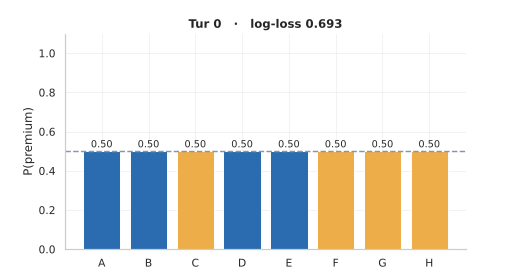

In [10]:
m_anim = LGBMClassifier(n_estimators=25, **OYUNCAK_AYAR).fit(X_oyuncak, y_oyuncak)
tur_listesi = [0, 1, 2, 3, 4, 6, 8, 10, 13, 17, 21, 25]


def kare_tur(fig, i):
    fig.clf(); ax = fig.add_subplot(111)
    t = tur_listesi[i]
    p = np.full(8, p0) if t == 0 else m_anim.predict_proba(X_oyuncak, num_iteration=t)[:, 1]
    ax.bar(mahalle["Mahalle"], p, color=[RENK["altin"] if v else RENK["mavi"] for v in y_oyuncak], edgecolor="white")
    ax.axhline(0.5, color=RENK["gri"], ls="--")
    for j, v in enumerate(p): ax.text(j, v + 0.02, f"{v:.2f}", ha="center", fontsize=10)
    ax.set(title=f"Tur {t}   ·   log-loss {log_loss(y_oyuncak, p):.3f}", ylabel="P(premium)", ylim=(0, 1.1))


gif_kaydet(kare_tur, len(tur_listesi), "kavram_06_tur_tur_olasilik", figsize=(7.4, 4), fps=1.5)

<a id="p7"></a>

<p align="center">
  <img src="assets/kavram_07.svg" width="100%" alt="Bölüm 7">
</p>

### 🪣 7.1 · Sayıları Kovalara Atmak

Bir sütunda 506 farklı oda sayısı varsa, "RM ≤ ?" sorusu için **505 aday eşik** denenmelidir; üstelik her denemede tüm satırlar taranır. LightGBM önce her sütunu **en fazla 255 kovaya** (`max_bin`) böler: değerler artık "kova numarasıdır". Kova başına **artık toplamı** ve **belirsizlik toplamı** bir kez hesaplanır; aday eşik sayısı **kova sayısı − 1**'e iner.

<p align="center">
  <img src="assets/diyagram_histogram.svg" width="100%" alt="Histogram hilesi">
</p>

RM sütunu: 506 satır, 446 farklı değer  →  tam arama: 445 aday eşik  ·  255 kovayla ≤ 254 · 16 kovayla ≤ 15


💾 Kaydedildi → outputs/figures/kavram_07_kova_profili.png


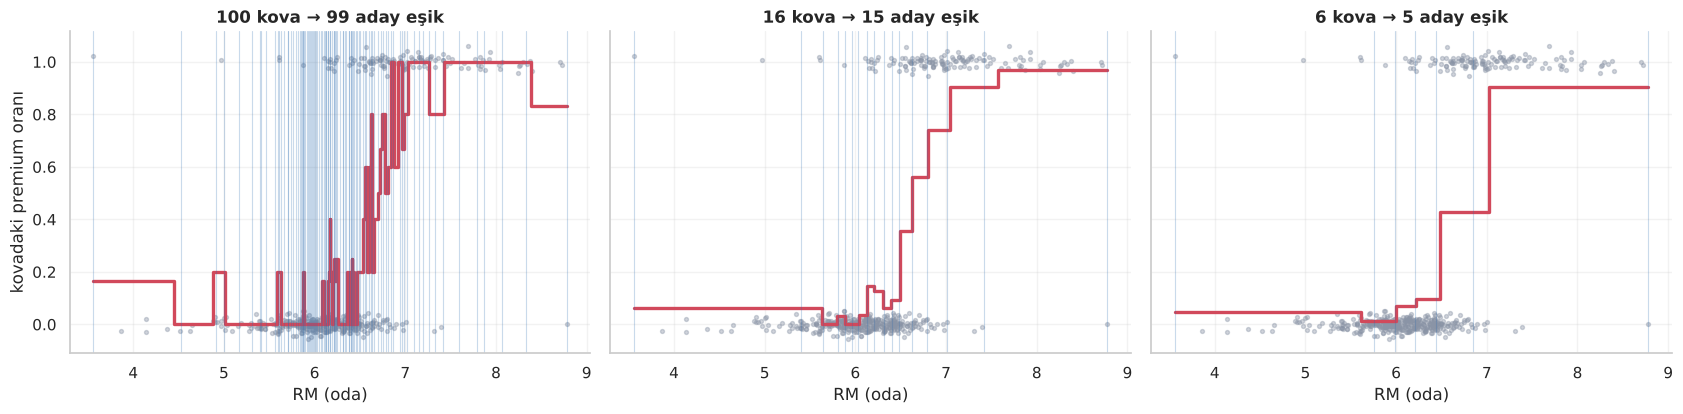

In [11]:
boston = veri_oku("23-boston.csv")
yb = (boston["MEDV"] >= 25).astype(int).to_numpy(); rm_tum = boston["RM"].to_numpy()
print(f"RM sütunu: {len(rm_tum)} satır, {len(np.unique(rm_tum))} farklı değer  →  tam arama: {len(np.unique(rm_tum)) - 1} aday eşik  ·  255 kovayla ≤ 254 · 16 kovayla ≤ 15")


def kova_profili(n_kova):
    """RM'i eşit sayıda mahalle içeren kovalara böler; kova başına premium oranını döndürür."""
    kenar = np.unique(np.quantile(rm_tum, np.linspace(0, 1, n_kova + 1)))
    kova = np.clip(np.searchsorted(kenar, rm_tum, side="right") - 1, 0, len(kenar) - 2)
    merkez = np.array([rm_tum[kova == k].mean() for k in range(len(kenar) - 1)])
    oran = np.array([yb[kova == k].mean() for k in range(len(kenar) - 1)])
    return kenar, merkez, oran


fig, eksen = plt.subplots(1, 3, figsize=(17, 4.3), sharey=True)
for ax, nk in zip(eksen, [100, 16, 6]):
    kenar, merkez, oran = kova_profili(nk)
    ax.scatter(rm_tum, yb + np.random.default_rng(1).normal(0, 0.02, len(yb)), s=8, color=RENK["gri"], alpha=0.4)
    ax.step(np.r_[kenar[0], merkez, kenar[-1]], np.r_[oran[0], oran, oran[-1]], where="mid", color=RENK["pembe"], lw=2.4)
    for e in kenar: ax.axvline(e, color=RENK["mavi"], alpha=0.25, lw=0.8)
    ax.set(title=f"{len(kenar) - 1} kova → {len(kenar) - 2} aday eşik", xlabel="RM (oda)")
eksen[0].set_ylabel("kovadaki premium oranı")
plt.tight_layout()
kaydet(fig, "kavram_07_kova_profili")
plt.show()

### 🎞️ 7.2 · Kovaları Kalınlaştırmak (Animasyon)

Kova sayısını **446'dan 4'e** düşürürken "premium oranı" eğrisine bakın: **ince ayrıntılar** kaybolur ama **ana şekil** (oda sayısı arttıkça premium oranı fırlıyor) uzun süre **korunur**. İşte histogramın hız karşılığında ödediği küçük bedel.

💾 Animasyon → outputs/figures/kavram_08_kovalar.gif (65 KB)


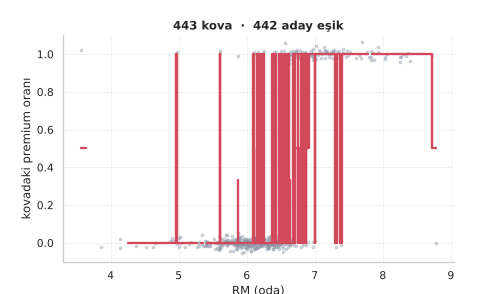

In [12]:
kova_sayilari = [446, 200, 100, 50, 25, 16, 10, 6, 4]


def kare_kova(fig, i):
    fig.clf(); ax = fig.add_subplot(111)
    nk = kova_sayilari[i]; kenar, merkez, oran = kova_profili(nk)
    ax.scatter(rm_tum, yb + np.random.default_rng(1).normal(0, 0.02, len(yb)), s=8, color=RENK["gri"], alpha=0.35)
    ax.step(np.r_[kenar[0], merkez, kenar[-1]], np.r_[oran[0], oran, oran[-1]], where="mid", color=RENK["pembe"], lw=2.4)
    ax.set(title=f"{len(kenar) - 1} kova  ·  {max(len(kenar) - 2, 0)} aday eşik", xlabel="RM (oda)", ylabel="kovadaki premium oranı", ylim=(-0.1, 1.1))


gif_kaydet(kare_kova, len(kova_sayilari), "kavram_08_kovalar", figsize=(7.2, 4.2), fps=1.2)

### ⏱️ 7.3 · Deney: Kova Sayısı Hız ve Başarıyı Nasıl Etkiler?

60 bin satırlık yapay bir veride `max_bin` değerini değiştirip **eğitim süresine** ve **AUC**'ye bakıyoruz.

max_bin,4,8,16,32,63,127,255,511,1023
eğitim süresi (sn),0.4902,0.4232,0.3645,0.3859,0.4146,0.4484,0.4891,0.5466,0.8489
test AUC,0.9702,0.9800,0.9811,0.9815,0.9813,0.9809,0.9812,0.9805,0.9808


💾 Kaydedildi → outputs/figures/kavram_09_max_bin_hiz.png


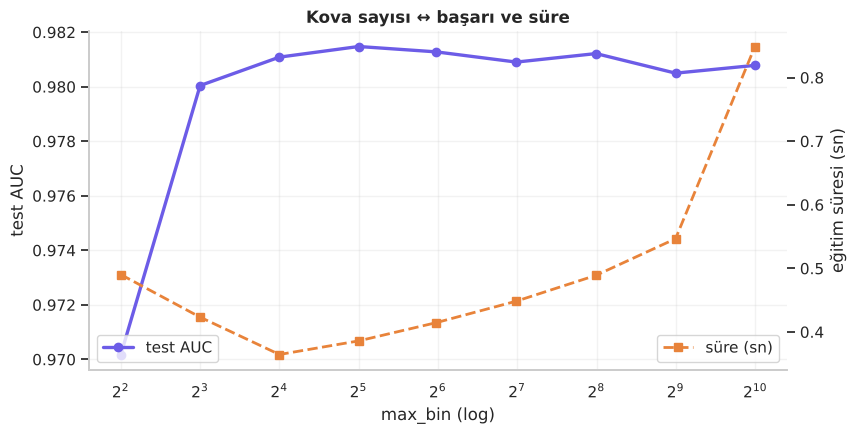

In [13]:
Xb, yb_big = make_classification(n_samples=60000, n_features=30, n_informative=12, n_redundant=4, flip_y=0.03, class_sep=0.9, random_state=RANDOM_STATE)
Xb_e, Xb_t, yb_e, yb_t = train_test_split(Xb, yb_big, test_size=0.25, random_state=RANDOM_STATE)
satir = []
for mb in [4, 8, 16, 32, 63, 127, 255, 511, 1023]:
    m = LGBMClassifier(n_estimators=150, learning_rate=0.1, max_bin=mb, n_jobs=4, verbosity=-1, random_state=RANDOM_STATE)
    t0 = time.perf_counter(); m.fit(Xb_e, yb_e); sure = time.perf_counter() - t0
    satir.append({"max_bin": mb, "eğitim süresi (sn)": sure, "test AUC": roc_auc_score(yb_t, m.predict_proba(Xb_t)[:, 1])})
mb_tablo = pd.DataFrame(satir).set_index("max_bin")
display(mb_tablo.round(4).T)

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(mb_tablo.index, mb_tablo["test AUC"], "o-", color=RENK["mor"], lw=2.4, label="test AUC")
ax.set_xscale("log", base=2); ax.set(title="Kova sayısı ↔ başarı ve süre", xlabel="max_bin (log)", ylabel="test AUC")
ax2 = ax.twinx(); ax2.plot(mb_tablo.index, mb_tablo["eğitim süresi (sn)"], "s--", color=RENK["turuncu"], lw=2, label="süre (sn)"); ax2.set_ylabel("eğitim süresi (sn)"); ax2.grid(False)
ax.legend(loc="lower left"); ax2.legend(loc="lower right")
kaydet(fig, "kavram_09_max_bin_hiz")
plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Kova sayısı arttıkça süre artıyor, başarı ise bir yerde doygunluğa ulaşıyor.** Çok az kovada (4) ince ayrıntı kaybolduğundan AUC belirgin düşüyor; **8 kovadan sonra** başarı doygunluğa ulaşıyor ve 63–255 arasında fark **çok küçük**. Bu yüzden varsayılan `max_bin = 255` genellikle iyi bir dengedir. (Süre ölçümleri bilgisayarınıza göre değişir; sıralama aynı kalır.)

</td></tr></table>

<a id="p8"></a>

<p align="center">
  <img src="assets/kavram_08.svg" width="100%" alt="Bölüm 8">
</p>

### 🍃 8.1 · Katman Katman mı, Yaprak Yaprak mı?

Çoğu ağaç algoritması **katman katman** (level-wise) büyür: önce kök, sonra tüm ikinci seviye düğümler, sonra tüm üçüncü seviye… Hepsi bölünür; faydalı olsun olmasın. LightGBM ise **yaprak yaprak** (leaf-wise) büyür: her adımda **mevcut tüm yapraklar arasında en çok kazanç sağlayacak yaprağı** seçer ve yalnızca onu böler. İtfaiye benzetmesi: *her katta bir itfaiyeci göndermek yerine, en büyük yangının çıktığı odaya git.*

<p align="center">
  <img src="assets/diyagram_yaprak.svg" width="100%" alt="Katman katman ve yaprak yaprak büyüme">
</p>

8 mahallemizde ikinci bölünmeyi **hangi yaprak** alır? Elle bakalım. (Küçük bir not: 8 örnekte `λ = 1` freni ikinci bölünmenin kazancını **negatif** yapıyor ve hiçbir yaprak bölünmüyor; bu da frenlerin küçük veride ne kadar güçlü olduğunu gösteriyor. Yaprak yarışını görebilmek için bu gösterimde `λ = 0` kullanıyoruz.)

In [14]:
def yaprak_en_iyi(maske, lam=0.0):
    """Verilen yapraktaki mahalleler için en iyi eşiği ve gain'i döndürür (yaprağın kendi artıklarıyla)."""
    idx = np.where(maske)[0]; en = (0.0, None)
    for k in range(1, len(idx)):
        sol, sag = idx[:k], idx[k:]
        puan = lambda i: r[i].sum() ** 2 / (h[i].sum() + lam)
        g = puan(sol) + puan(sag) - puan(idx)
        if g > en[0]: en = (g, (rm[idx[k - 1]] + rm[idx[k]]) / 2)
    return en


print("λ = 1 iken ikinci bölünme:", yaprak_en_iyi(sol_mask, lam=1.0), "← gain pozitif bir bölünme yok: fren devrede (8 örnekte λ güçlü bir fren)")
kazanc_sol, esik_sol = yaprak_en_iyi(sol_mask)          # ABCDE yaprağı (bu gösterimde λ = 0)
kazanc_sag, esik_sag = yaprak_en_iyi(~sol_mask)         # FGH yaprağı
print(f"\nλ = 0 iken  →  sol yaprak (ABCDE, 5 mahalle): en iyi bölünme RM ≤ {esik_sol} → gain {kazanc_sol:.3f}")
print(f"                 sağ yaprak (FGH, 3 mahalle):   gain {kazanc_sag:.3f}   (hepsi zaten premium: bölmeye değmez)")

m3 = LGBMClassifier(n_estimators=1, **{**OYUNCAK_AYAR, "num_leaves": 3, "reg_lambda": 0.0}).fit(X_oyuncak, y_oyuncak)
ag3 = m3.booster_.trees_to_dataframe()
display(ag3[["node_index", "split_feature", "threshold", "split_gain", "count"]])
print("LightGBM'in ikinci bölünmesi: eşik", ag3[ag3.split_feature.notna()].iloc[1]["threshold"], "→ 5 mahallelik sol yaprak (ABCDE) bölündü; 3 mahallelik sağ yaprak olduğu gibi kaldı.")

λ = 1 iken ikinci bölünme: (0.0, None) ← gain pozitif bir bölünme yok: fren devrede (8 örnekte λ güçlü bir fren)

λ = 0 iken  →  sol yaprak (ABCDE, 5 mahalle): en iyi bölünme RM ≤ 5.949999999999999 → gain 0.533
                 sağ yaprak (FGH, 3 mahalle):   gain 0.000   (hepsi zaten premium: bölmeye değmez)


,node_index,split_feature,threshold,split_gain,count
0,0-S0,RM,6.85,4.800000,8
1,0-S1,RM,6.25,0.533333,5
2,0-L0,NaN,NaN,NaN,3
3,0-L2,NaN,NaN,NaN,2
4,0-L1,NaN,NaN,NaN,3


LightGBM'in ikinci bölünmesi: eşik 6.250000000000001 → 5 mahallelik sol yaprak (ABCDE) bölündü; 3 mahallelik sağ yaprak olduğu gibi kaldı.


### 📈 8.2 · Aynı Yaprak Sayısında Hangisi Daha İyi Öğrenir?

Boston verisinde **tek bir ağaç** eğitiyoruz (`n_estimators=1`, öğrenme hızı 1) ve aynı yaprak sayısında iki stratejiyi karşılaştırıyoruz: **serbest yaprak yaprak büyüme** (`max_depth = −1`) ve **derinlik sınırlı, katman katman benzeri** (`max_depth = d`, `num_leaves = 2^d`). Ölçüt: **eğitim log-loss'u** (ağaç ne kadar iyi uydu?) ve ulaşılan **derinlik**.

eğitim log-loss  \
strateji      katman katman benzeri (derinlik sınırlı)   
yaprak sayısı                                            
2                                                0.338   
4                                                0.277   
8                                                0.221   
16                                               0.196   
32                                               0.175   

                                       \
strateji      yaprak yaprak (serbest)   
yaprak sayısı                           
2                               0.338   
4                               0.273   
8                               0.214   
16                              0.170   
32                              0.154   

                                       gerçek derinlik                          
strateji      katman katman benzeri (derinlik sınırlı) yaprak yaprak (serbest)  
yaprak sayısı                                                                   
2                                                  1.0                     1.0  
4                                                  2.0                     3.0  
8                                                  3.0                     4.0  
16                                                 4.0                     7.0  
32                                                 5.0                     9.0

💾 Kaydedildi → outputs/figures/kavram_10_yaprak_yaprak_karsilastirma.png


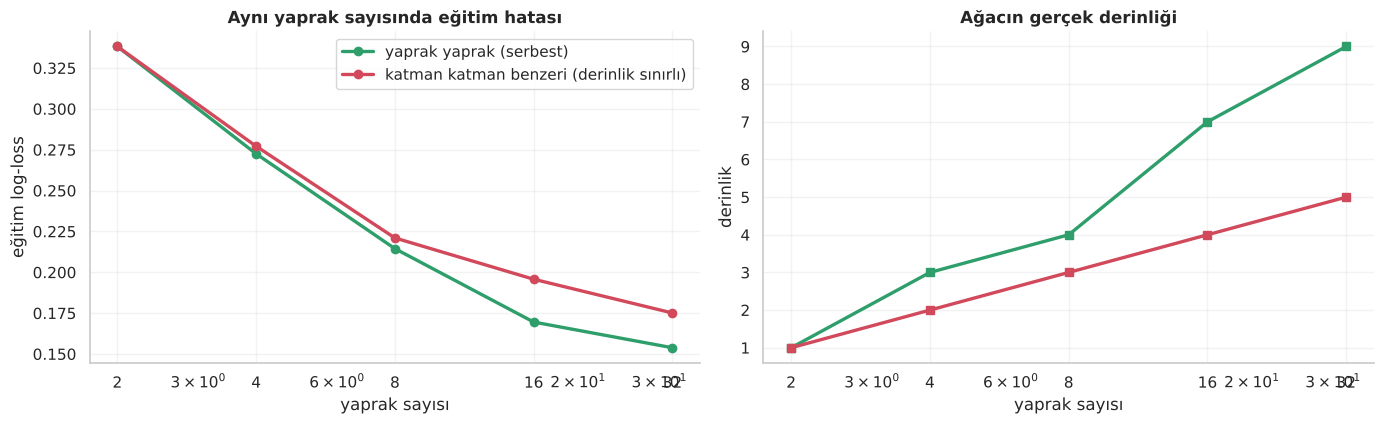

In [15]:
X_b = boston.drop(columns=["MEDV", "B"]); yb_boston = (boston["MEDV"] >= 25).astype(int).to_numpy()
satir = []
for d in [1, 2, 3, 4, 5]:
    L = 2 ** d
    for ad, kw in [("yaprak yaprak (serbest)", dict(max_depth=-1)), ("katman katman benzeri (derinlik sınırlı)", dict(max_depth=d))]:
        m = LGBMClassifier(n_estimators=1, learning_rate=1.0, num_leaves=L, min_child_samples=5, min_child_weight=0, verbosity=-1, n_jobs=1, **kw).fit(X_b, yb_boston)
        td = m.booster_.trees_to_dataframe()
        satir.append({"yaprak sayısı": L, "strateji": ad, "eğitim log-loss": log_loss(yb_boston, m.predict_proba(X_b)[:, 1]), "gerçek derinlik": int(td["node_depth"].max()) - 1,
                      "gerçek yaprak": int(td["split_feature"].isna().sum())})
buyume = pd.DataFrame(satir)
display(buyume.pivot(index="yaprak sayısı", columns="strateji", values=["eğitim log-loss", "gerçek derinlik"]).round(3))

fig, eksen = plt.subplots(1, 2, figsize=(14, 4.4))
for ad, renk in [("yaprak yaprak (serbest)", RENK["yesil"]), ("katman katman benzeri (derinlik sınırlı)", RENK["pembe"])]:
    t = buyume[buyume["strateji"] == ad]
    eksen[0].plot(t["yaprak sayısı"], t["eğitim log-loss"], "o-", lw=2.4, color=renk, label=ad); eksen[1].plot(t["yaprak sayısı"], t["gerçek derinlik"], "s-", lw=2.4, color=renk, label=ad)
eksen[0].set(title="Aynı yaprak sayısında eğitim hatası", xlabel="yaprak sayısı", ylabel="eğitim log-loss", xscale="log", xticks=[2, 4, 8, 16, 32], xticklabels=[2, 4, 8, 16, 32]); eksen[0].legend()
eksen[1].set(title="Ağacın gerçek derinliği", xlabel="yaprak sayısı", ylabel="derinlik", xscale="log", xticks=[2, 4, 8, 16, 32], xticklabels=[2, 4, 8, 16, 32])
plt.tight_layout()
kaydet(fig, "kavram_10_yaprak_yaprak_karsilastirma")
plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Aynı yaprak sayısında **yaprak yaprak büyüyen** ağaç eğitim verisine **daha iyi** uyuyor (log-loss daha düşük) ve bunu **daha derin** bir yapıyla başarıyor: kazancın olduğu yerde derine iniyor, olmadığı yerde durmuyor. Bu hem **gücü** hem **riski**dir: derin, dengesiz ağaç küçük veride **ezber** yapabilir. Bu yüzden LightGBM'de `num_leaves`, `max_depth` ve `min_child_samples` birlikte düşünülür (bölüm 11).

</td></tr></table>

### 🎞️ 8.3 · Ağaç Yaprak Yaprak Büyürken (Animasyon)

`RM` ve `LSTAT` ile eğitilen **tek bir ağacın** olasılık haritası, yaprak sayısı 2'den 12'ye çıkarken nasıl şekilleniyor? Her yeni yaprak, **en çok kazanç sağlayan bölgeyi** ikiye böler; büyük kesin bölgeler kaba kalır, karışık bölgeler ince ince bölünür.

💾 Animasyon → outputs/figures/kavram_11_yaprak_yaprak_buyume.gif (90 KB)


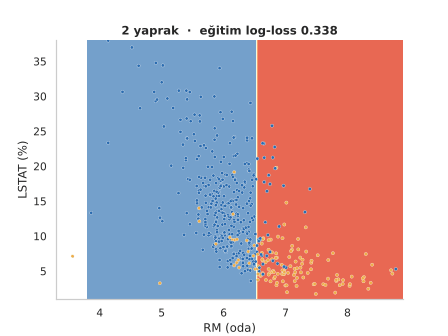

In [16]:
gx, gy = np.meshgrid(np.linspace(3.8, 8.9, 140), np.linspace(1, 38, 140)); izgara2 = pd.DataFrame({"RM": gx.ravel(), "LSTAT": gy.ravel()})
iki = boston[["RM", "LSTAT"]]; yaprak_listesi = [2, 3, 4, 5, 6, 8, 10, 12]


def kare_yaprak(fig, i):
    fig.clf(); ax = fig.add_subplot(111)
    L = yaprak_listesi[i]
    m = LGBMClassifier(n_estimators=1, learning_rate=1.0, num_leaves=L, min_child_samples=8, min_child_weight=0, verbosity=-1, n_jobs=1).fit(iki, yb_boston)
    p = m.predict_proba(izgara2)[:, 1].reshape(gx.shape)
    ax.contourf(gx, gy, p, levels=np.linspace(0, 1, 11), cmap="RdYlBu_r", alpha=0.85)
    ax.scatter(iki["RM"], iki["LSTAT"], c=[RENK["altin"] if v else RENK["mavi"] for v in yb_boston], s=11, edgecolor="white", linewidth=0.3)
    ax.set(title=f"{L} yaprak  ·  eğitim log-loss {log_loss(yb_boston, m.predict_proba(iki)[:, 1]):.3f}", xlabel="RM (oda)", ylabel="LSTAT (%)"); ax.grid(False)


gif_kaydet(kare_yaprak, len(yaprak_listesi), "kavram_11_yaprak_yaprak_buyume", figsize=(6.4, 4.8), fps=1.3)

<a id="p9"></a>

<p align="center">
  <img src="assets/kavram_09.svg" width="100%" alt="Bölüm 9">
</p>

### 🎯 9.1 · Tüm Örneklere Bakmak Şart mı?

Boosting'de her örneğin bir **gradyanı** (kabaca "ne kadar yanıldık" ölçüsü) vardır. **Küçük gradyanlı** örnekler zaten doğru öğrenilmiş; bir sonraki ağaca çok az bilgi katar. **GOSS** (Gradient-based One-Side Sampling) bu fikri kullanır: gradyanı **en büyük %a** örneği **hepsini** tutar, geri kalanlardan yalnızca **%b**'sini rastgele seçer ve bu seçilenlerin ağırlığını `(1 − a) / b` ile **büyütür** (az sayıda örnek, çok sayıdakini temsil etsin diye).

<p align="center">
  <img src="assets/diyagram_goss.svg" width="100%" alt="GOSS">
</p>

404 örnek → büyük gradyanlı 80 (hepsi tutulur) + küçük gradyanlılardan 40 (ağırlık × 8) = 120 örnek (30%)
Tüm örneklerle en iyi RM eşiği: 6.594 (gain 2.22)
GOSS ile (300 tekrar): medyan eşik 6.594 · eşiklerin %38'i ±0,15 içinde · gain ortalaması 2.46


💾 Kaydedildi → outputs/figures/kavram_12_goss.png


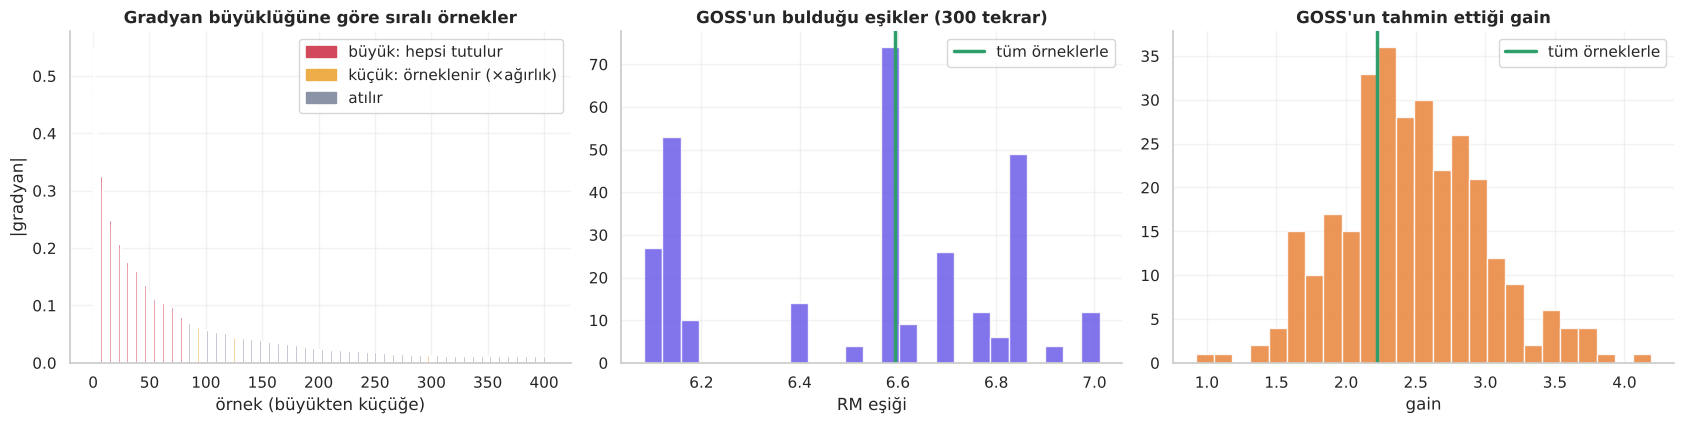

In [17]:
# Gerçek bir ara modelin gradyanlarıyla GOSS: 30 turluk model → her mahalle için |p − y|
X_e9, X_t9, y_e9, y_t9 = train_test_split(X_b, yb_boston, test_size=0.2, stratify=yb_boston, random_state=RANDOM_STATE)
ara_model = LGBMClassifier(n_estimators=30, learning_rate=0.1, min_child_samples=10, verbosity=-1, n_jobs=1).fit(X_e9, y_e9)
p_ara = ara_model.predict_proba(X_e9)[:, 1]; g_mut = np.abs(p_ara - y_e9)                  # gradyan büyüklüğü (log-loss için |p − y|)
A_ORAN, B_ORAN = 0.20, 0.10
sira = np.argsort(-g_mut); n9 = len(g_mut); n_buyuk = int(A_ORAN * n9)
buyuk_idx = sira[:n_buyuk]; kucuk_havuz = sira[n_buyuk:]
rng = np.random.default_rng(5); secilen_kucuk = rng.choice(kucuk_havuz, size=int(B_ORAN * n9), replace=False)
agirlik = (1 - A_ORAN) / B_ORAN
print(f"{n9} örnek → büyük gradyanlı {len(buyuk_idx)} (hepsi tutulur) + küçük gradyanlılardan {len(secilen_kucuk)} (ağırlık × {agirlik:.0f}) = {len(buyuk_idx) + len(secilen_kucuk)} örnek ({(len(buyuk_idx) + len(secilen_kucuk)) / n9 * 100:.0f}%)")


def en_iyi_esik(x, g, h, w):
    """Tek özellikte ağırlıklı gain taraması → (en iyi eşik, gain). g,h: gradyan/hessian; w: örnek ağırlığı."""
    o = np.argsort(x); x, g, h, w = x[o], g[o], h[o], w[o]
    G, H = np.cumsum(g * w), np.cumsum(h * w); Gt, Ht = G[-1], H[-1]; k = np.arange(len(x) - 1)
    ok = x[k] != x[k + 1]
    kazanc = G[k] ** 2 / (H[k] + 1) + (Gt - G[k]) ** 2 / (Ht - H[k] + 1) - Gt ** 2 / (Ht + 1)
    kazanc = np.where(ok, kazanc, -np.inf); j = int(np.argmax(kazanc))
    return (x[j] + x[j + 1]) / 2, kazanc[j]


g_gercek = p_ara - y_e9; h_gercek = p_ara * (1 - p_ara); x_rm = X_e9["RM"].to_numpy()
tam_esik, tam_gain = en_iyi_esik(x_rm, g_gercek, h_gercek, np.ones(n9))
goss_esikler, goss_gainler = [], []
for tohum in range(300):                                                                       # GOSS örneklemesini 300 kez tekrarla
    rr = np.random.default_rng(tohum); sec = rr.choice(kucuk_havuz, size=int(B_ORAN * n9), replace=False)
    idx = np.r_[buyuk_idx, sec]; w = np.r_[np.ones(len(buyuk_idx)), np.full(len(sec), agirlik)]
    e, k_ = en_iyi_esik(x_rm[idx], g_gercek[idx], h_gercek[idx], w); goss_esikler.append(e); goss_gainler.append(k_)
print(f"Tüm örneklerle en iyi RM eşiği: {tam_esik:.3f} (gain {tam_gain:.2f})")
print(f"GOSS ile (300 tekrar): medyan eşik {np.median(goss_esikler):.3f} · eşiklerin %{(np.abs(np.array(goss_esikler) - tam_esik) < 0.15).mean() * 100:.0f}'i ±0,15 içinde · gain ortalaması {np.mean(goss_gainler):.2f}")

fig, eksen = plt.subplots(1, 3, figsize=(17, 4.4))
renk_sec = np.full(n9, RENK["gri"], dtype=object); renk_sec[buyuk_idx] = RENK["pembe"]; renk_sec[secilen_kucuk] = RENK["altin"]
eksen[0].bar(range(n9), g_mut[sira], color=renk_sec[sira], width=1.0)
eksen[0].set(title="Gradyan büyüklüğüne göre sıralı örnekler", xlabel="örnek (büyükten küçüğe)", ylabel="|gradyan|")
eksen[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=RENK["pembe"], label="büyük: hepsi tutulur"), plt.Rectangle((0, 0), 1, 1, color=RENK["altin"], label="küçük: örneklenir (×ağırlık)"), plt.Rectangle((0, 0), 1, 1, color=RENK["gri"], label="atılır")])
eksen[1].hist(goss_esikler, bins=25, color=RENK["mor"], alpha=0.85); eksen[1].axvline(tam_esik, color=RENK["yesil"], lw=2.5, label="tüm örneklerle"); eksen[1].set(title="GOSS'un bulduğu eşikler (300 tekrar)", xlabel="RM eşiği"); eksen[1].legend()
eksen[2].hist(goss_gainler, bins=25, color=RENK["turuncu"], alpha=0.85); eksen[2].axvline(tam_gain, color=RENK["yesil"], lw=2.5, label="tüm örneklerle"); eksen[2].set(title="GOSS'un tahmin ettiği gain", xlabel="gain"); eksen[2].legend()
plt.tight_layout()
kaydet(fig, "kavram_12_goss")
plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

GOSS'un bulduğu eşiklerin **medyanı, tüm örneklerle bulunan eşikle aynı**; ama tek tek denemelerde eşik bir miktar **sağa-sola yayılıyor** ve tahmin edilen gain **biraz şişiyor** (ortalama ≈ 2,5 ↔ gerçek ≈ 2,2). Yani GOSS **tam doğru bir kısayol değil, yaklaşık bir kısayoldur**: çok sayıda ağaç boyunca bu küçük hatalar birbirini dengeler; ama 404 satır gibi küçük örneklemde yayılım belirgindir.

</td></tr></table>

### 🎞️ 9.2 · GOSS Seçimi (Animasyon)

💾 Animasyon → outputs/figures/kavram_13_goss_secimi.gif (31 KB)


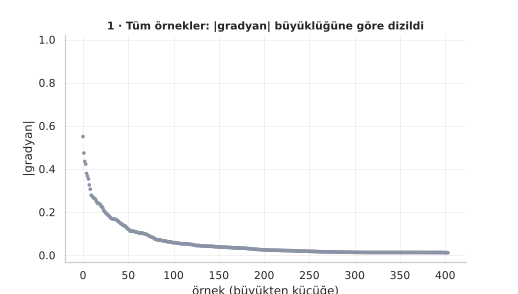

In [18]:
def kare_goss(fig, i):
    fig.clf(); ax = fig.add_subplot(111)
    asama = i; xs = np.arange(n9)
    renk = np.full(n9, RENK["gri"], dtype=object); boy = np.full(n9, 14.0); mesaj = "1 · Tüm örnekler: |gradyan| büyüklüğüne göre dizildi"
    if asama >= 1: renk[buyuk_idx] = RENK["pembe"]; mesaj = f"2 · En büyük %{A_ORAN * 100:.0f} gradyanlı örneğin HEPSİ tutulur"
    if asama >= 2: renk[secilen_kucuk] = RENK["altin"]; mesaj = f"3 · Kalanlardan %{B_ORAN * 100:.0f} (toplamın) rastgele seçilir"
    if asama >= 3:
        boy[secilen_kucuk] = 14 * 3; mesaj = f"4 · Seçilen küçüklerin ağırlığı × {agirlik:.0f}: azlar çokları temsil eder"
        mask_atilan = np.setdiff1d(np.arange(n9), np.r_[buyuk_idx, secilen_kucuk]); renk[mask_atilan] = "#DDDDDD"
    ax.scatter(xs, g_mut[sira], c=renk[sira], s=boy[sira], edgecolor="none")
    ax.set(title=mesaj, xlabel="örnek (büyükten küçüğe)", ylabel="|gradyan|", ylim=(-0.03, 1.02)); ax.title.set_fontsize(11)


gif_kaydet(kare_goss, 4, "kavram_13_goss_secimi", figsize=(7.4, 4.2), fps=0.9)

### ⏱️ 9.3 · Gerçek Kütüphanede GOSS

In [19]:
satir = []
for ad, kw in [("gbdt (tüm örnekler)", {}), ("goss", dict(data_sample_strategy="goss"))]:
    ts, aucs = [], []
    for tohum in range(3):
        m = LGBMClassifier(n_estimators=300, learning_rate=0.1, n_jobs=4, verbosity=-1, random_state=tohum, **kw)
        t0 = time.perf_counter(); m.fit(Xb_e, yb_e); ts.append(time.perf_counter() - t0); aucs.append(roc_auc_score(yb_t, m.predict_proba(Xb_t)[:, 1]))
    satir.append({"yöntem": ad, "süre (sn, 3 deneme)": np.mean(ts), "test AUC": np.mean(aucs)})
goss_tablo = pd.DataFrame(satir).set_index("yöntem")
display(goss_tablo.round(4))

,"süre (sn, 3 deneme)",test AUC
yöntem,,
gbdt (tüm örnekler),0.7223,0.9824
goss,0.7514,0.9825


<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Tablodaki sonuç dürüst bir uyarı: **60 bin satırda GOSS süre kazandırmadı** (hatta hafif yavaş kalabilir), AUC ise **aynı**. GOSS'un faydası **milyonlarca satırlık** veride görünür; küçük/orta veride örnekleme işlemi kendi başına maliyet getirir. **404 satırlık** bir veri setinde (proje notebook'u) GOSS'a gerek yoktur: hile **ölçeğe** bağlı. LightGBM'de GOSS, sürüm 4'ten beri `data_sample_strategy="goss"` ile açılır.

</td></tr></table>

<a id="p10"></a>

<p align="center">
  <img src="assets/kavram_10.svg" width="100%" alt="Bölüm 10">
</p>

### 📦 10.1 · Seyrek Sütunları Paketlemek

Kategorik sütunlar **one-hot** ile açıldığında yüzlerce sütun olur ve her satırda **yalnızca biri doludur**. Bu sütunlar **aynı anda hiç dolu olmuyorsa** (birbirini dışlıyorsa), tek bir sütuna **ofsetlerle** sığdırılabilir: "ilk sütun 0–1, ikinci 2–3, üçüncü 4–5…" Bilgi kaybı olmaz; sütun sayısı düşer. İşte **EFB** (Exclusive Feature Bundling).

<p align="center">
  <img src="assets/diyagram_efb.svg" width="100%" alt="EFB">
</p>

💾 Kaydedildi → outputs/figures/kavram_14_efb_paketleme.png


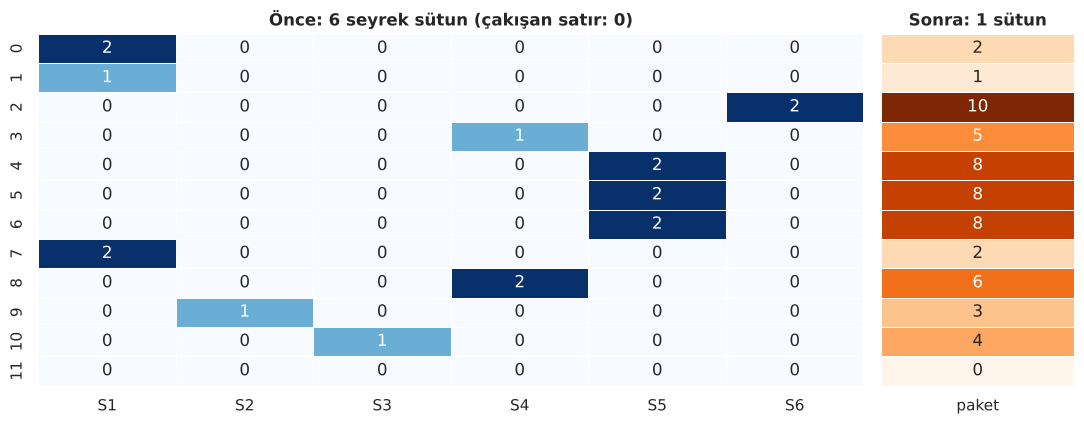

Ofsetler: [0, 2, 3, 4, 6, 8] · paketlenmiş değer 0 ise 'hepsi boş' demek


In [20]:
# 6 seyrek sütun, 12 satır: her satırda en fazla biri dolu (birbirini dışlıyorlar)
rng = np.random.default_rng(11)
secim = rng.integers(0, 7, 12)                                    # 0..5: hangi sütun dolu; 6: hepsi boş
seyrek = np.zeros((12, 6), int)
for i, s in enumerate(secim):
    if s < 6: seyrek[i, s] = rng.integers(1, 3)
cakisma = int(((seyrek > 0).sum(axis=1) > 1).sum())
ofset = np.r_[0, np.cumsum(seyrek.max(axis=0))[:-1]]
paket = np.where(seyrek > 0, seyrek + ofset, 0).sum(axis=1)       # tek sütun: değer = ofset + eski değer

fig, eksen = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [6, 1.4]})
sns.heatmap(seyrek, annot=True, cmap="Blues", cbar=False, ax=eksen[0], xticklabels=[f"S{j + 1}" for j in range(6)], linewidths=0.5); eksen[0].set(title=f"Önce: 6 seyrek sütun (çakışan satır: {cakisma})"); eksen[0].grid(False)
sns.heatmap(paket[:, None], annot=True, cmap="Oranges", cbar=False, ax=eksen[1], xticklabels=["paket"], yticklabels=False, linewidths=0.5); eksen[1].set(title="Sonra: 1 sütun"); eksen[1].grid(False)
plt.tight_layout()
kaydet(fig, "kavram_14_efb_paketleme")
plt.show()
print("Ofsetler:", ofset.tolist(), "· paketlenmiş değer 0 ise 'hepsi boş' demek")

### ⏱️ 10.2 · Gerçek Kütüphanede EFB

40 bin satır, **1200 seyrek sütun** (8 kategorik değişken × 150 düzey one-hot). `enable_bundle` açıkken ve kapalıyken **süre** ve **AUC**'ye bakıyoruz.

In [21]:
from scipy import sparse
rng = np.random.default_rng(21)
n_s, n_deg, n_duz = 40000, 8, 150
kodlar = rng.integers(0, n_duz, (n_s, n_deg))
etki = rng.normal(0, 1, (n_deg, n_duz))
skor = sum(etki[j, kodlar[:, j]] for j in range(n_deg)) + rng.normal(0, 1.2, n_s)
y_s = (skor > np.median(skor)).astype(int)
X_s = sparse.csr_matrix((np.ones(n_s * n_deg), (np.repeat(np.arange(n_s), n_deg), (kodlar + np.arange(n_deg) * n_duz).ravel())), shape=(n_s, n_deg * n_duz))
Xs_e, Xs_t, ys_e, ys_t = train_test_split(X_s, y_s, test_size=0.25, random_state=RANDOM_STATE)

satir = []
for ad, kw in [("EFB açık (varsayılan)", dict(enable_bundle=True)), ("EFB kapalı", dict(enable_bundle=False))]:
    ts, aucs = [], []
    for tohum in range(3):
        m = LGBMClassifier(n_estimators=200, learning_rate=0.1, n_jobs=4, verbosity=-1, random_state=tohum, **kw)
        t0 = time.perf_counter(); m.fit(Xs_e, ys_e); ts.append(time.perf_counter() - t0); aucs.append(roc_auc_score(ys_t, m.predict_proba(Xs_t)[:, 1]))
    satir.append({"yöntem": ad, "süre (sn, 3 deneme)": np.mean(ts), "test AUC": np.mean(aucs)})
efb_tablo = pd.DataFrame(satir).set_index("yöntem")
display(efb_tablo.round(4))
print(f"Sütun sayısı: {X_s.shape[1]} · satır: {X_s.shape[0]} · doluluk: %{X_s.nnz / (X_s.shape[0] * X_s.shape[1]) * 100:.2f}")

,"süre (sn, 3 deneme)",test AUC
yöntem,,
EFB açık (varsayılan),0.4662,0.9142
EFB kapalı,0.5438,0.9142


Sütun sayısı: 1200 · satır: 40000 · doluluk: %0.67


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

EFB'nin **başarıyı değiştirmemesi** beklenir (bilgi kaybı yok) ve tabloda AUC değerleri **aynı** çıkar. Süre farkı bu ölçekte **küçük** ve sütun sayısına/seyrekliğe göre değişir: **çok sayıda seyrek one-hot sütun** olduğunda anlamlıdır, **birkaç düzine sütunlu** tablolarda (bizim Boston verimiz gibi) yoktur. Dördüncü hile de böylece **ölçek hilesi** olduğunu gösterdi.

</td></tr></table>

<a id="p11"></a>

<p align="center">
  <img src="assets/kavram_11.svg" width="100%" alt="Bölüm 11">
</p>

### 🛡️ 11.1 · Küçük Veride İlk Tuzak: Ağaç Hiç Büyümüyor

LightGBM'in varsayılanları **büyük veri** düşünülerek seçilmiştir. En önemlisi `min_child_samples = 20`: *bir yaprakta en az 20 örnek olmalı.* 8 mahallemizde bu kural **hiçbir bölünmeye izin vermez**. Deneyelim:

In [22]:
varsayilan = LGBMClassifier(n_estimators=5, learning_rate=ETA, verbosity=-1, n_jobs=1).fit(X_oyuncak, y_oyuncak)
agac_v = varsayilan.booster_.trees_to_dataframe()
print("Varsayılan LightGBM ile ağaçtaki düğüm sayısı (tur başına):", agac_v.groupby("tree_index").size().tolist())
print("Tahmin edilen olasılıklar:", np.round(varsayilan.predict_proba(X_oyuncak)[:, 1], 3))
print("→ Hiçbir bölünme yapılmadı; model herkese 'ortalama' diyor (%50).")

serbest = LGBMClassifier(n_estimators=5, **OYUNCAK_AYAR).fit(X_oyuncak, y_oyuncak)
print("\nmin_child_samples=1 ile:", np.round(serbest.predict_proba(X_oyuncak)[:, 1], 3))

Varsayılan LightGBM ile ağaçtaki düğüm sayısı (tur başına): [1]
Tahmin edilen olasılıklar: [0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]
→ Hiçbir bölünme yapılmadı; model herkese 'ortalama' diyor (%50).

min_child_samples=1 ile: [0.324 0.324 0.324 0.324 0.324 0.737 0.737 0.737]


<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

**Ders:** *Bir kütüphanenin varsayılanı, sizin verinizin varsayılanı değildir.* Küçük veride model "öğrenmiyormuş" gibi görünüyorsa önce `min_child_samples`, `min_data_in_bin` ve `min_child_weight` gibi **güvenlik frenlerine** bakın.

</td></tr></table>

### 🎛️ 11.2 · Kontrol Paneli: Hangi Düğme Ne Yapar?

<p align="center">
  <img src="assets/diyagram_dugmeler.svg" width="100%" alt="LightGBM kontrol paneli">
</p>

| Düğme | Ne yapar? | Küçük veride |
|:--|:--|:--|
| `num_leaves` | Ağacın **yaprak sayısı** (karmaşıklık) | Küçük tut (4–16) |
| `max_depth` | Derinlik emniyet kemeri | 3–6 |
| `min_child_samples` | Yaprakta **en az örnek** | Büyüt (10–40) |
| `learning_rate` + `n_estimators` | Adım büyüklüğü × tur | Küçük hız, erken durdurma |
| `subsample` / `colsample_bytree` | Satır / sütun örnekleme | 0,6–0,9 |
| `reg_lambda`, `reg_alpha`, `min_split_gain` | Frenler (L2, L1, asgari kazanç) | 1–5, küçük, > 0 |

💾 Kaydedildi → outputs/figures/kavram_15_yaprak_ornek_izgarasi.png


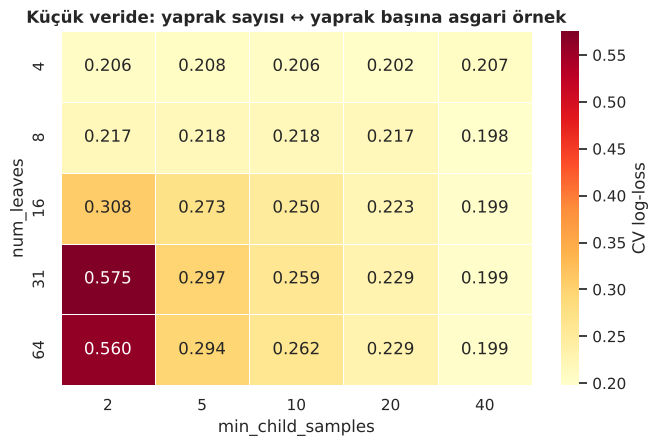

En iyi hücre: num_leaves=8, min_child_samples=40 → 0.198  ·  en kötü: 0.575


In [23]:
# num_leaves × min_child_samples: 5 katlı CV log-loss (Boston, 12 sütun)
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
yaprak_l, mcs_l = [4, 8, 16, 31, 64], [2, 5, 10, 20, 40]
izgara_kayip = pd.DataFrame(index=yaprak_l, columns=mcs_l, dtype=float)
for nl in yaprak_l:
    for mcs in mcs_l:
        m = LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=nl, min_child_samples=mcs, verbosity=-1, n_jobs=1, random_state=RANDOM_STATE)
        izgara_kayip.loc[nl, mcs] = -cross_val_score(m, X_b, yb_boston, cv=cv5, scoring="neg_log_loss").mean()
fig, ax = plt.subplots(figsize=(7.6, 4.6))
sns.heatmap(izgara_kayip, annot=True, fmt=".3f", cmap="YlOrRd", ax=ax, linewidths=0.5, cbar_kws={"label": "CV log-loss"}); ax.grid(False)
ax.set(title="Küçük veride: yaprak sayısı ↔ yaprak başına asgari örnek", xlabel="min_child_samples", ylabel="num_leaves")
kaydet(fig, "kavram_15_yaprak_ornek_izgarasi")
plt.show()
print(f"En iyi hücre: num_leaves={izgara_kayip.stack().idxmin()[0]}, min_child_samples={izgara_kayip.stack().idxmin()[1]} → {izgara_kayip.stack().min():.3f}  ·  en kötü: {izgara_kayip.stack().max():.3f}")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Isı haritasında **sol-alt köşe** (çok yaprak + çok küçük yaprak) en kötü; **sağ taraf** (büyük `min_child_samples`) belirgin şekilde daha iyi. Yani **ağacı büyütmek** değil, **büyümesini sınırlamak** küçük veride kazandırıyor. Bu, proje notebook'unun ana derslerinden biri.

</td></tr></table>

<a id="p12"></a>

<p align="center">
  <img src="assets/kavram_12.svg" width="100%" alt="Bölüm 12">
</p>

### ⚡ 12.1 · Hız Yarışı

Aynı veride (60 bin satır × 30 sütun) **beş kütüphane** aynı sayıda tur (200) ve benzer derinlikte yarışıyor. Süre, bilgisayarınıza göre değişir; **sıralamaya** ve **AUC'nin benzerliğine** bakın.

,"süre (sn, en iyi 3'te)",test AUC
kütüphane,,
LightGBM,0.5425,0.9816
XGBoost (hist),0.6341,0.9820
HistGradientBoosting (sklearn),0.7974,0.9814
CatBoost,1.0850,0.9822


💾 Kaydedildi → outputs/figures/kavram_16_hiz.png


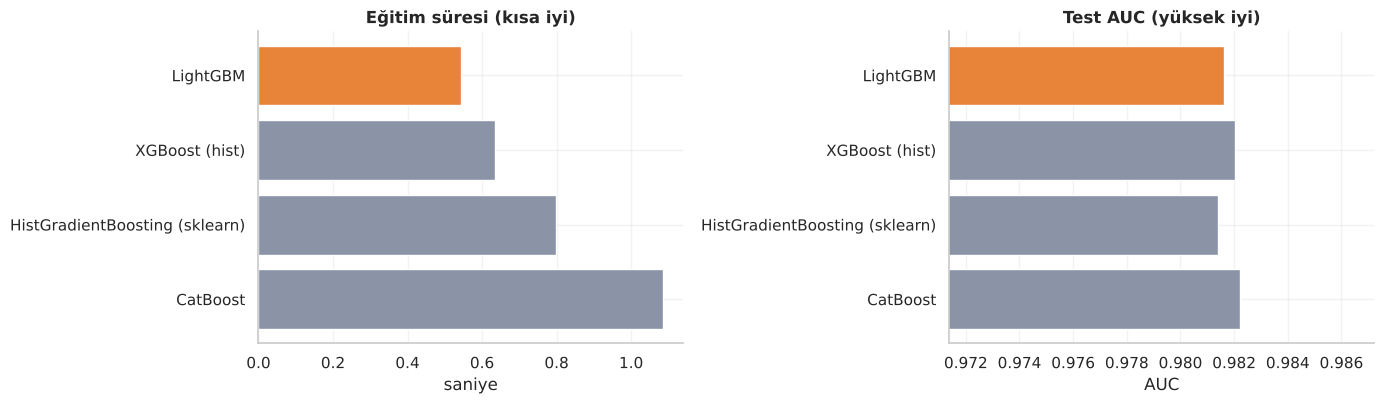

In [24]:
yarisciler = {
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, num_leaves=31, n_jobs=4, verbosity=-1, random_state=RANDOM_STATE),
    "XGBoost (hist)": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, tree_method="hist", n_jobs=4, random_state=RANDOM_STATE, verbosity=0),
    "HistGradientBoosting (sklearn)": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_leaf_nodes=31, random_state=RANDOM_STATE),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, thread_count=4, verbose=0, random_seed=RANDOM_STATE, allow_writing_files=False),
}
satir = []
for ad, m in yarisciler.items():
    ts = []
    for _ in range(3):
        mm = m.__class__(**m.get_params()); t0 = time.perf_counter(); mm.fit(Xb_e, yb_e); ts.append(time.perf_counter() - t0)
    satir.append({"kütüphane": ad, "süre (sn, en iyi 3'te)": min(ts), "test AUC": roc_auc_score(yb_t, mm.predict_proba(Xb_t)[:, 1])})
hiz = pd.DataFrame(satir).set_index("kütüphane").sort_values("süre (sn, en iyi 3'te)")
display(hiz.round(4))

fig, eksen = plt.subplots(1, 2, figsize=(14, 4.2))
eksen[0].barh(hiz.index[::-1], hiz["süre (sn, en iyi 3'te)"].iloc[::-1], color=[RENK["turuncu"] if "LightGBM" in k else RENK["gri"] for k in hiz.index[::-1]])
eksen[0].set(title="Eğitim süresi (kısa iyi)", xlabel="saniye")
eksen[1].barh(hiz.index[::-1], hiz["test AUC"].iloc[::-1], color=[RENK["turuncu"] if "LightGBM" in k else RENK["gri"] for k in hiz.index[::-1]])
eksen[1].set(title="Test AUC (yüksek iyi)", xlabel="AUC", xlim=(hiz["test AUC"].min() - 0.01, hiz["test AUC"].max() + 0.005))
plt.tight_layout()
kaydet(fig, "kavram_16_hiz")
plt.show()

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Hız ölçümleri **donanıma, iş parçacığı sayısına ve veri boyutuna** bağlıdır; "LightGBM her zaman en hızlıdır" demek yanlış olur. Doğru cümle: *büyük tablolarda, histogram + yaprak yaprak büyüme sayesinde LightGBM genellikle çok hızlıdır ve benzer başarı verir.* Küçük veride (404 satır) hız **hiç önemli değildir**; orada asıl iş **ezberi önlemektir**.

</td></tr></table>

<a id="p13"></a>

<p align="center">
  <img src="assets/kavram_13.svg" width="100%" alt="Bölüm 13">
</p>

Anlamanın en iyi sınavı: **kendiniz yazmak**. Aşağıda yaklaşık 60 satırlık bir **mini LightGBM** var: histogram (aday eşikler), gradyan/hessian, yaprak yaprak büyüme ve yaprak değeri. Sonra bunu **gerçek kütüphaneyle** karşılaştıracağız.

In [25]:
class MiniLGBM:
    """İkili sınıflandırma için küçük bir LightGBM: yaprak yaprak büyüme + gradyan/hessian + λ düzenlemesi."""

    def __init__(self, n_tur=30, hiz=0.1, yaprak=6, lam=1.0, min_ornek=5, min_hess=1e-3):
        self.n_tur, self.hiz, self.yaprak, self.lam, self.min_ornek, self.min_hess = n_tur, hiz, yaprak, lam, min_ornek, min_hess

    def _en_iyi_bolunme(self, idx, g, h):
        """Bir yapraktaki örnekler için tüm sütun ve kovalarda en yüksek gain'i arar (histogram: kova başına g ve h toplamı)."""
        G, H = g[idx].sum(), h[idx].sum(); en = (0.0, None, None)
        for j in range(self.Xb.shape[1]):
            kova = self.Xb[idx, j]
            Gk, Hk = np.bincount(kova, g[idx], self.n_kova[j]), np.bincount(kova, h[idx], self.n_kova[j])
            Nk = np.bincount(kova, minlength=self.n_kova[j])
            GL, HL, NL = np.cumsum(Gk)[:-1], np.cumsum(Hk)[:-1], np.cumsum(Nk)[:-1]       # "kova k'ya kadar sol yaprakta" toplamları
            GR, HR, NR = G - GL, H - HL, len(idx) - NL
            gecerli = (NL >= self.min_ornek) & (NR >= self.min_ornek) & (HL >= self.min_hess) & (HR >= self.min_hess)
            kazanc = np.where(gecerli, GL ** 2 / (HL + self.lam) + GR ** 2 / (HR + self.lam) - G ** 2 / (H + self.lam), -np.inf)
            k = int(np.argmax(kazanc))
            if kazanc[k] > en[0]: en = (kazanc[k], j, k)
        return en

    def _kovala(self, X):
        return np.stack([np.searchsorted(self.esikler[j], X[:, j], side="left") for j in range(X.shape[1])], 1)

    def fit(self, X, y):
        X = np.asarray(X, float)
        self.esikler = [(np.unique(X[:, j])[:-1] + np.unique(X[:, j])[1:]) / 2 for j in range(X.shape[1])]       # aday eşikler = ardışık değerlerin orta noktaları
        self.Xb = self._kovala(X); self.n_kova = [len(e) + 1 for e in self.esikler]
        self.f0 = np.log(y.mean() / (1 - y.mean())); F = np.full(len(y), self.f0); self.agaclar = []
        for _ in range(self.n_tur):
            p = sigmoid(F); g, h = p - y, p * (1 - p)                                                               # gradyan ve hessian
            yapraklar = [{"idx": np.arange(len(y))}]; yapraklar[0]["bol"] = self._en_iyi_bolunme(yapraklar[0]["idx"], g, h); bolunmeler = []
            while len(yapraklar) < self.yaprak:
                kaz = [y_["bol"][0] if y_["bol"][1] is not None else -np.inf for y_ in yapraklar]
                k = int(np.argmax(kaz))                                                                              # YAPRAK YAPRAK: en çok kazandıran yaprak seçilir
                if kaz[k] <= 0: break
                _, j, kova = yapraklar[k]["bol"]; idx = yapraklar[k]["idx"]
                sol, sag = idx[self.Xb[idx, j] <= kova], idx[self.Xb[idx, j] > kova]
                bolunmeler.append((k, j, kova, len(yapraklar)))
                yapraklar[k] = {"idx": sol, "bol": self._en_iyi_bolunme(sol, g, h)}
                yapraklar.append({"idx": sag, "bol": self._en_iyi_bolunme(sag, g, h)})
            degerler = []
            for y_ in yapraklar:                                                                                     # yaprak değeri = Σartık / (Σhessian + λ) × η
                d = -g[y_["idx"]].sum() / (h[y_["idx"]].sum() + self.lam) * self.hiz
                F[y_["idx"]] += d; degerler.append(d)
            self.agaclar.append({"bolunmeler": bolunmeler, "degerler": np.array(degerler)})
        return self

    def ham_skor(self, X):
        Xb = self._kovala(np.asarray(X, float)); F = np.full(len(Xb), self.f0)
        for a in self.agaclar:
            yaprak = np.zeros(len(Xb), int)
            for k, j, kova, yeni in a["bolunmeler"]:
                yaprak[(yaprak == k) & (Xb[:, j] > kova)] = yeni
            F += a["degerler"][yaprak]
        return F

    def predict_proba(self, X):
        return sigmoid(self.ham_skor(X))


print("MiniLGBM tanımlandı.")

MiniLGBM tanımlandı.


### ✅ 13.1 · Doğrulama: Mini LightGBM = Gerçek LightGBM mi?

Boston'ın ilk 200 satırı, 4 sütun. Her iki model **aynı ayarlarla** eğitilir; çıktıları (olasılıklar) karşılaştırılır. Tabloda ayrıca **bilerek** daha büyük bir ayar (4 yaprak, 20 tur) bırakıyoruz: dürüst olmak için örtüşmenin **nerede bozulduğunu** da görmek istiyoruz.

,yaprak,tur,en büyük olasılık farkı,ortalama fark,mini doğruluk,gerçek doğruluk
0,2,100,3.41e-09,2.95e-10,0.955,0.955
1,3,25,2.06e-09,7.25e-10,0.950,0.950
2,4,10,5.71e-09,1.11e-09,0.930,0.930
3,4,20,1.59e-02,2.72e-03,0.950,0.950


💾 Kaydedildi → outputs/figures/kavram_17_mini_lightgbm_dogrulama.png


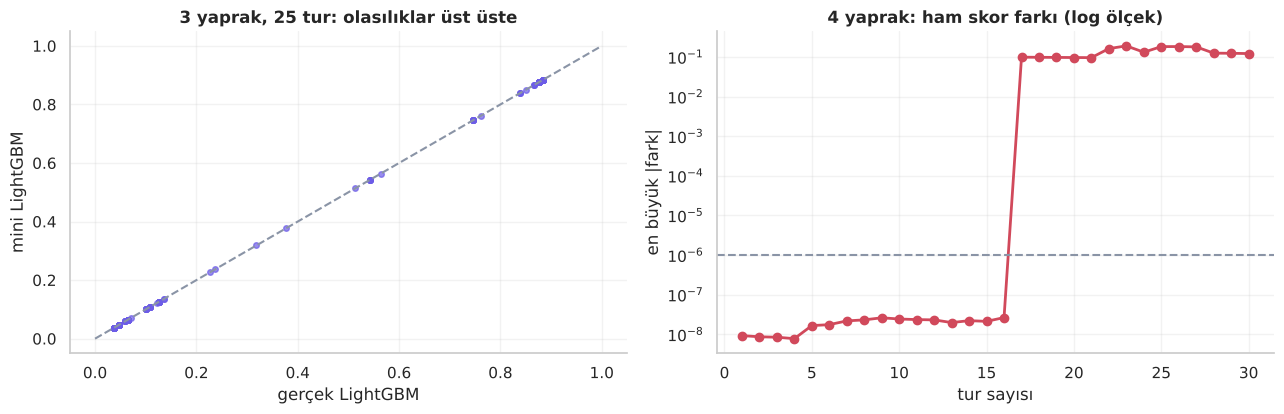

4 yaprakta fark 1e-6'yı ilk aşan tur: 17


In [26]:
alt = boston.iloc[:200]; X_alt = alt[["RM", "LSTAT", "PTRATIO", "CRIM"]]; y_alt = (alt["MEDV"] >= 25).astype(int).to_numpy()
satir = []
for yaprak, tur in [(2, 100), (3, 25), (4, 10), (4, 20)]:
    mini = MiniLGBM(n_tur=tur, hiz=0.1, yaprak=yaprak, min_ornek=5).fit(X_alt, y_alt)
    gercek = LGBMClassifier(n_estimators=tur, learning_rate=0.1, num_leaves=yaprak, min_child_samples=5, reg_lambda=1.0, min_data_in_bin=1, n_jobs=1, verbosity=-1).fit(X_alt, y_alt)
    fark = np.abs(mini.predict_proba(X_alt) - gercek.predict_proba(X_alt)[:, 1])
    satir.append({"yaprak": yaprak, "tur": tur, "en büyük olasılık farkı": fark.max(), "ortalama fark": fark.mean(),
                  "mini doğruluk": ((mini.predict_proba(X_alt) > 0.5) == y_alt).mean(), "gerçek doğruluk": gercek.score(X_alt, y_alt)})
dogrulama = pd.DataFrame(satir)
display(dogrulama.style.format({"en büyük olasılık farkı": "{:.2e}", "ortalama fark": "{:.2e}", "mini doğruluk": "{:.3f}", "gerçek doğruluk": "{:.3f}"}))

# 4 yapraklı modelde fark tur tur nasıl büyüyor?
farklar = []
for t in range(1, 31):
    mini = MiniLGBM(n_tur=t, hiz=0.1, yaprak=4, min_ornek=5).fit(X_alt, y_alt)
    gercek = LGBMClassifier(n_estimators=t, learning_rate=0.1, num_leaves=4, min_child_samples=5, reg_lambda=1.0, min_data_in_bin=1, n_jobs=1, verbosity=-1).fit(X_alt, y_alt)
    farklar.append(np.abs(mini.ham_skor(X_alt) - gercek.predict(X_alt, raw_score=True)).max())
fig, eksen = plt.subplots(1, 2, figsize=(13, 4.3))
m_son = MiniLGBM(n_tur=25, hiz=0.1, yaprak=3, min_ornek=5).fit(X_alt, y_alt)
g_son = LGBMClassifier(n_estimators=25, learning_rate=0.1, num_leaves=3, min_child_samples=5, reg_lambda=1.0, min_data_in_bin=1, n_jobs=1, verbosity=-1).fit(X_alt, y_alt)
eksen[0].scatter(g_son.predict_proba(X_alt)[:, 1], m_son.predict_proba(X_alt), s=16, color=RENK["mor"], alpha=0.7); eksen[0].plot([0, 1], [0, 1], "--", color=RENK["gri"])
eksen[0].set(title="3 yaprak, 25 tur: olasılıklar üst üste", xlabel="gerçek LightGBM", ylabel="mini LightGBM")
eksen[1].semilogy(range(1, 31), np.maximum(farklar, 1e-12), "o-", color=RENK["pembe"], lw=2); eksen[1].axhline(1e-6, color=RENK["gri"], ls="--")
eksen[1].set(title="4 yaprak: ham skor farkı (log ölçek)", xlabel="tur sayısı", ylabel="en büyük |fark|")
plt.tight_layout()
kaydet(fig, "kavram_17_mini_lightgbm_dogrulama")
plt.show()
ilk_sapma = next((t for t, f in enumerate(farklar, 1) if f > 1e-6), None)
print(f"4 yaprakta fark 1e-6'yı ilk aşan tur: {ilk_sapma}")

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

**Mini LightGBM, gerçek kütüphaneyle 2–3 yapraklı ağaçlarda 25–100 tur boyunca ~10⁻⁹ hassasiyetle (4 yapraklıda ilk 16 tur) örtüşüyor**: gradyan, hessian, gain, yaprak değeri, öğrenme hızı ve yaprak yaprak büyüme **gerçekten bu kadar**. Daha büyük ağaçlarda belli bir turdan sonra (4 yaprakta 17. tur) örtüşme bozuluyor: iki ağaç **farklı bir yaprağı bölmeyi tercih ediyor** (gerçek kütüphanenin iç sayım ve histogram ayrıntıları bizim sadeleştirmemizden farklı; bu ayrıntıyı bu derste çözmüyoruz). Doğruluk ise yine de **aynı** kalıyor: iki modelin kararları pratikte aynı. Bu, "kütüphaneyi bir kara kutu olarak değil, anladığımız bir mekanizma olarak" kullandığımızın kanıtı.

</td></tr></table>

<a id="p14"></a>

<p align="center">
  <img src="assets/kavram_14.svg" width="100%" alt="Bölüm 14">
</p>

### 🧠 14.1 · Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🔁</h3><b>Aynı döngü</b><br><sub><i>tahmin → artık → ağaç → güncelle</i></sub><br><br>LightGBM, XGBoost ve CatBoost aynı boosting döngüsünü kullanır; fark <b>mühendislikte</b><br><br></td><td width="33%" valign="top" align="center"><h3>🪣</h3><b>Histogram</b><br><sub><i>kovala, say, böl</i></sub><br><br>Sayıları ≤ 255 kovaya atmak aday eşik sayısını düşürür; başarı neredeyse aynı kalır<br><br></td><td width="33%" valign="top" align="center"><h3>🍃</h3><b>Yaprak yaprak</b><br><sub><i>en çok kazandıran yaprak</i></sub><br><br>Aynı yaprak sayısında daha iyi uyar, ama <b>daha derin ve ezbere yatkın</b> olur<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>🎯</h3><b>GOSS</b><br><sub><i>büyük hata tut, küçüğü örnekle</i></sub><br><br>Büyük veride süre kazandırır; küçük veride gerekmez<br><br></td><td width="33%" valign="top" align="center"><h3>📦</h3><b>EFB</b><br><sub><i>seyrek sütunları paketle</i></sub><br><br>Çok sayıda one-hot sütunda işe yarar; bilgi kaybı yoktur<br><br></td><td width="33%" valign="top" align="center"><h3>🛡️</h3><b>Küçük veride frenler</b><br><sub><i>min_child_samples · λ · num_leaves</i></sub><br><br>Varsayılanlar büyük veri içindir; küçük veride <b>sınırlamak</b> kazandırır<br><br></td></tr>
</table>

### 🆚 14.2 · Sınıflandırma ile Regresyon

Bu notebook **sınıflandırma** (premium mu?) ile yürüdü. **Regresyon** (fiyatı tahmin et) için döngü aynıdır; yalnızca **artık = gerçek − tahmin** (log-odds yerine doğrudan sayı) ve belirsizlik toplamı yerine **örnek sayısı** kullanılır. `LGBMRegressor` bunu yapar.

### ❓ 14.3 · Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> Boosting'de her yeni ağaç neyi tahmin etmeye çalışır?</summary>

Önceki modelin **artıklarını** (hatalarını). Her çırak, öncekilerin bıraktığı eksiği kapatır; hepsinin katkıları toplanarak son tahmin elde edilir.
</details>

<details><summary><b>2.</b> Başlangıç tahmini neden "ortalama"dır?</summary>

Hiçbir özellik bilinmeden en az hata yapan sabit tahmin ortalamadır (ikili sınıflandırmada premium oranı). LightGBM bunu log-odds olarak tutar; %50 → 0.
</details>

<details><summary><b>3.</b> Gain neyi ölçer?</summary>

Bir bölünmenin artıkları **ne kadar düzenli gruplara** ayırdığını. Aynı işaretli artıkları bir araya getiren bölünme yüksek gain alır; karışık işaretler birbirini götürür.
</details>

<details><summary><b>4.</b> Histogram hilesi neyi hızlandırır, bedeli nedir?</summary>

Aday eşik sayısını (≈ farklı değer sayısı → ≤ kova sayısı) düşürür ve kova toplamlarını bir kez hesaplamayı sağlar. Bedeli, çok ince eşiklerin kaybıdır; 63–255 kovada bu kayıp genellikle önemsizdir.
</details>

<details><summary><b>5.</b> Yaprak yaprak büyümenin küçük veride riski nedir?</summary>

Ağaç tek bir bölgede çok derine inip birkaç örneğe özel yapraklar kurabilir (ezber). `min_child_samples`, `num_leaves`, `max_depth` bu yüzden birlikte ayarlanır.
</details>

<details><summary><b>6.</b> GOSS'ta seçilen küçük gradyanlı örneklerin ağırlığı neden büyütülür?</summary>

Atılan çok sayıdaki küçük gradyanlı örneği **temsil etmek** için: seçilen az sayıda örnek `(1 − a) / b` katı ağırlıkla sayılır; böylece gain tahmini yanlı olmaz.
</details>

<details><summary><b>7.</b> 8 satırlık veride varsayılan LightGBM neden hiç bölünmedi?</summary>

`min_child_samples = 20`: bir yaprakta en az 20 örnek olmalı; 8 örnekle hiçbir bölünme bu şartı sağlayamaz. Ağaçlar tek yapraklı kalır ve model herkese ortalamayı söyler.
</details>

### 🏠 14.4 · Ödevler

1. 🍃 8 mahallelik örnekte **η = 0,1** ve **η = 1,0** ile 25 tur oynatın. C mahallesinin olasılığı hangi hızda nereye ulaşıyor? Animasyonu yeniden üretin.
2. 🪣 Boston'daki `LSTAT` sütunu için kova sayısını 255 → 8 azaltıp `LGBMClassifier(max_bin=…)` ile CV skorlarını karşılaştırın.
3. 🎯 GOSS'ta `a` ve `b` değerlerini (0,1/0,05; 0,3/0,2) değiştirin. Eşik tahmininin yayılımı nasıl değişiyor?
4. 📦 EFB deneyinde düzey sayısını 150'den 20'ye düşürün. Süre farkı kayboluyor mu?
5. 🧪 `MiniLGBM`'e **`min_split_gain`** (γ) ekleyin: gain bu eşikten küçükse yaprak bölünmesin. Gerçek `min_split_gain` ile karşılaştırın.
6. 🌲 `MiniLGBM`'i **katman katman** büyüyen bir sürüme çevirin (her turda tüm yapraklar bölünsün). Aynı yaprak sayısında eğitim hatasını karşılaştırın.

### 📚 KAYNAKÇA

Metin içi atıflar APA 7 biçimindedir. **Dolaylı atıf** "(B, A'dan aktarma)" kalıbıyla gösterilir; örnek: *Gradyan artırma fikri (Friedman, 2001, Ke vd., 2017'den aktarma) LightGBM'in temelini oluşturur.*

- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794. https://doi.org/10.1145/2939672.2939785
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Harrison, D., Jr., & Rubinfeld, D. L. (1978). Hedonic housing prices and the demand for clean air. *Journal of Environmental Economics and Management, 5*(1), 81–102. https://doi.org/10.1016/0095-0696(78)90006-2
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*, 3146–3154.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: Unbiased boosting with categorical features. *Advances in Neural Information Processing Systems, 31*, 6638–6648.

<p align="center">
  <img src="assets/kapanis_kavram.svg" width="100%" alt="Gün 51 kavram dersi tamamlandı">
</p>

In [27]:
for dosya in sorted(FIG_DIR.glob("kavram_*")):
    print(f"{dosya.as_posix():<62} {dosya.stat().st_size / 1024:>8.1f} KB")

outputs/figures/kavram_01_tek_model_mi_ekip_mi.png                150.4 KB
outputs/figures/kavram_02_sigmoid.png                              51.3 KB
outputs/figures/kavram_03_ilk_artiklar.png                         39.4 KB
outputs/figures/kavram_04_aday_bolunmeler.png                      36.8 KB
outputs/figures/kavram_05_bolunme_tarayici.gif                     54.0 KB
outputs/figures/kavram_06_tur_tur_olasilik.gif                     55.2 KB
outputs/figures/kavram_07_kova_profili.png                        129.9 KB
outputs/figures/kavram_08_kovalar.gif                              65.5 KB
outputs/figures/kavram_09_max_bin_hiz.png                          86.1 KB
outputs/figures/kavram_10_yaprak_yaprak_karsilastirma.png         148.7 KB
outputs/figures/kavram_11_yaprak_yaprak_buyume.gif                 89.7 KB
outputs/figures/kavram_12_goss.png                                114.8 KB
outputs/figures/kavram_13_goss_secimi.gif                          30.7 KB
outputs/figures/kavram_14